# Notebook 01 - Static Characterization

**Milestone:** HV-004  
**Technical Gate:** SC-001  
**Primary Engineering Question:** EQ-02 - Static Measurement Performance  
**Secondary Engineering Question:** EQ-04 - Hysteresis / Direction Dependence

This notebook characterizes the pre-calibration static measurement behavior of the DUT using only qualified analyst-visible evidence from the frozen `VSM-LAB-DATA-v1.1` release.

The notebook must preserve the analyst-blind boundary and the calibration/validation separation established during DQ-001.

## 1. Engineering Question

### Primary Question

How large is the DUT measurement error, and how does it vary with relative humidity and temperature?

### Secondary Question

Does the static error differ between increasing and decreasing humidity directions under matched conditions?

The primary observed error is defined as:

```text
Error_RH = RH_DUT - RH_Reference
```

A positive error means that the DUT indication is higher than the reference indication.

The reference indication is not treated as exact physical truth.

## 2. Why This Matters

Static characterization establishes the baseline measurement behavior of the DUT before any calibration correction is developed.

This stage is intended to determine whether the observed DUT-reference difference is approximately constant or whether it varies systematically with operating conditions such as relative humidity, temperature, and direction of environmental change.

A defensible characterization must also distinguish sample-level variation from independent experimental replication and must prevent calibration or validation data from leaking into the characterization analysis.

## 3. Scope and Analysis Boundary

### Included in HV-004

- qualified `STATIC` observations
- `CHARACTERIZATION` observations only
- pre-calibration DUT-reference error
- RH dependence
- temperature dependence
- matched Up/Down direction dependence
- day/run context
- descriptive static error metrics

### Deferred to later milestones

- formal repeatability/reproducibility variance decomposition
- calibration-model fitting
- model freeze
- independent validation
- dynamic-response analysis
- stability/drift analysis
- final uncertainty budget
- final DUT compliance decision

The working analysis frame must contain zero `CALIBRATION` and zero `VALIDATION` rows.

## 4. Input Data

Primary measurement file:

```text
data/raw/vsm_lab_data_v1_1/static_measurements.csv
```

Supporting experimental-design file:

```text
data/raw/vsm_lab_data_v1_1/test_matrix.csv
```

The frozen release passed DQ-001 before this notebook was started.

### SC-01 Objective

Load the frozen static data, isolate the qualified characterization subset, and verify that the working analysis frame respects the HV-004 role boundary.

In [1]:
from pathlib import Path

import pandas as pd


# ------------------------------------------------------------
# Locate project root and frozen dataset release
# ------------------------------------------------------------

current_dir = Path.cwd()

candidate_roots = [
    current_dir,
    current_dir.parent,
]

project_root = next(
    (
        path for path in candidate_roots
        if (path / "data" / "raw" / "vsm_lab_data_v1_1").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the project root containing "
        "'data/raw/vsm_lab_data_v1_1'."
    )

raw_data_dir = (
    project_root
    / "data"
    / "raw"
    / "vsm_lab_data_v1_1"
)

static_path = raw_data_dir / "static_measurements.csv"
test_matrix_path = raw_data_dir / "test_matrix.csv"

print(f"Project root : {project_root}")
print(f"Dataset path : {raw_data_dir}")
print(f"Static file  : {static_path.name}")
print(f"Test matrix  : {test_matrix_path.name}")

Project root : c:\MyDocument\hvac-sensor-validation-metrology
Dataset path : c:\MyDocument\hvac-sensor-validation-metrology\data\raw\vsm_lab_data_v1_1
Static file  : static_measurements.csv
Test matrix  : test_matrix.csv


### 4.1 Load Static Measurements and Test Matrix

The raw static file contains multiple analysis roles. HV-004 does not use all of them.

The purpose of this step is to load the source data without modifying the frozen files and then establish the role composition before filtering.

In [2]:
# ------------------------------------------------------------
# Load frozen analyst-facing inputs
# ------------------------------------------------------------

static_df = pd.read_csv(static_path)
test_matrix_df = pd.read_csv(test_matrix_path)

print(f"Static rows       : {len(static_df):,}")
print(f"Static columns    : {static_df.shape[1]}")
print(f"Static Test_IDs   : {static_df['Test_ID'].nunique():,}")
print(f"Test-matrix rows  : {len(test_matrix_df):,}")

print("\nStatic Analysis_Role counts:")
display(
    static_df["Analysis_Role"]
    .value_counts(dropna=False)
    .rename_axis("Analysis_Role")
    .reset_index(name="Rows")
)

print("\nStatic Test_ID counts by Analysis_Role:")
display(
    static_df.groupby("Analysis_Role")["Test_ID"]
    .nunique()
    .rename("Test_IDs")
    .reset_index()
)

Static rows       : 15,120
Static columns    : 15
Static Test_IDs   : 252
Test-matrix rows  : 333

Static Analysis_Role counts:


,Analysis_Role,Rows
0,CHARACTERIZATION,7200
1,CALIBRATION,5760
2,VALIDATION,2160



Static Test_ID counts by Analysis_Role:


,Analysis_Role,Test_IDs
0,CALIBRATION,96
1,CHARACTERIZATION,120
2,VALIDATION,36


### 4.2 Isolate the Characterization Working Frame

Only `STATIC / CHARACTERIZATION` observations are released into the HV-004 performance-analysis frame.

This is a deliberate methodological boundary:

- `CHARACTERIZATION` describes the raw DUT behavior.
- `CALIBRATION` is reserved for later model development.
- `VALIDATION` remains independent until the calibration model has been frozen.

This separation prevents data leakage.

In [3]:
# ------------------------------------------------------------
# Isolate qualified STATIC / CHARACTERIZATION observations
# ------------------------------------------------------------

characterization_df = static_df.loc[
    (static_df["Test_Family"] == "STATIC")
    & (static_df["Analysis_Role"] == "CHARACTERIZATION")
].copy()

role_counts_in_working_frame = (
    characterization_df["Analysis_Role"]
    .value_counts(dropna=False)
)

test_family_counts_in_working_frame = (
    characterization_df["Test_Family"]
    .value_counts(dropna=False)
)

print(f"Characterization rows     : {len(characterization_df):,}")
print(f"Characterization Test_IDs : {characterization_df['Test_ID'].nunique():,}")

print("\nTest_Family values in working frame:")
display(
    test_family_counts_in_working_frame
    .rename_axis("Test_Family")
    .reset_index(name="Rows")
)

print("\nAnalysis_Role values in working frame:")
display(
    role_counts_in_working_frame
    .rename_axis("Analysis_Role")
    .reset_index(name="Rows")
)

Characterization rows     : 7,200
Characterization Test_IDs : 120

Test_Family values in working frame:


,Test_Family,Rows
0,STATIC,7200



Analysis_Role values in working frame:


,Analysis_Role,Rows
0,CHARACTERIZATION,7200


### 4.3 SC-01 Role-Isolation Check

This check verifies completion criterion **C01 - Qualified characterization data only** and supports **C09 - Calibration and validation leakage is prevented**.

The working frame passes this check only if:

1. at least one characterization row is present;
2. every row has `Test_Family == STATIC`;
3. every row has `Analysis_Role == CHARACTERIZATION`;
4. no calibration rows are present;
5. no validation rows are present.

In [4]:
# ------------------------------------------------------------
# SC-01 role-isolation gate
# ------------------------------------------------------------

has_rows = len(characterization_df) > 0

static_only = (
    characterization_df["Test_Family"]
    .eq("STATIC")
    .all()
)

characterization_only = (
    characterization_df["Analysis_Role"]
    .eq("CHARACTERIZATION")
    .all()
)

calibration_rows_in_working_frame = (
    characterization_df["Analysis_Role"]
    .eq("CALIBRATION")
    .sum()
)

validation_rows_in_working_frame = (
    characterization_df["Analysis_Role"]
    .eq("VALIDATION")
    .sum()
)

sc01_role_isolation_pass = (
    has_rows
    and static_only
    and characterization_only
    and calibration_rows_in_working_frame == 0
    and validation_rows_in_working_frame == 0
)

print(f"Working frame has rows       : {has_rows}")
print(f"STATIC only                  : {static_only}")
print(f"CHARACTERIZATION only        : {characterization_only}")
print(
    "CALIBRATION rows in frame    : "
    f"{calibration_rows_in_working_frame}"
)
print(
    "VALIDATION rows in frame     : "
    f"{validation_rows_in_working_frame}"
)

print(
    "\nSC-01 role-isolation check    : "
    f"{'PASS' if sc01_role_isolation_pass else 'FAIL'}"
)

if not sc01_role_isolation_pass:
    raise RuntimeError(
        "SC-01 role-isolation check failed. "
        "Do not continue static characterization."
    )

Working frame has rows       : True
STATIC only                  : True
CHARACTERIZATION only        : True
CALIBRATION rows in frame    : 0
VALIDATION rows in frame     : 0

SC-01 role-isolation check    : PASS


### 4.4 Experimental-Condition Inventory

Before calculating performance metrics, inspect the experimental factors represented in the characterization subset.

For this notebook, an experimental condition is defined by a combination of factor levels such as RH setpoint, temperature setpoint, direction, day, and run.

This inventory is descriptive. It does not yet estimate sensor performance.

In [5]:
# ------------------------------------------------------------
# Inspect characterization design factors
# ------------------------------------------------------------

design_factors = [
    "RH_Setpoint",
    "Temperature_Setpoint_C",
    "Direction",
    "Day_ID",
    "Run_ID",
    "Chamber_State",
]

design_inventory = []

for column in design_factors:
    values = (
        characterization_df[column]
        .drop_duplicates()
        .sort_values()
        .tolist()
    )
    
    design_inventory.append(
        {
            "Factor": column,
            "Number_of_Levels": len(values),
            "Levels": values,
        }
    )

design_inventory_df = pd.DataFrame(design_inventory)

display(design_inventory_df)

,Factor,Number_of_Levels,Levels
0,RH_Setpoint,7,"[20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0]"
1,Temperature_Setpoint_C,3,"[15.0, 25.0, 35.0]"
2,Direction,2,"[DOWN, UP]"
3,Day_ID,3,"[1, 2, 3]"
4,Run_ID,2,"[1, 2]"
5,Chamber_State,1,[STABLE]


### SC-01 Engineering Interpretation

The frozen static dataset was loaded successfully from the controlled
`VSM-LAB-DATA-v1.1` release.

The complete static dataset contains 15,120 measurement rows across 252
Test_IDs. The HV-004 working frame was restricted to the
`CHARACTERIZATION` analysis role, resulting in 7,200 observations across
120 Test_IDs.

The role-isolation check passed. The working frame contains only
`STATIC / CHARACTERIZATION` observations, with zero `CALIBRATION` and zero
`VALIDATION` rows. Therefore, the analysis boundary required for HV-004 is
preserved and no calibration or validation data have leaked into the
characterization stage.

The characterization data span seven RH setpoints (20–80 %RH), three
temperature setpoints (15, 25, and 35 °C), both Up and Down directions,
three test days, and two run identifiers. All characterization records
are associated with the `STABLE` chamber state.

There are 7,200 measurement rows across 120 Test_IDs, corresponding to
60 samples per Test_ID. These repeated samples belong to individual test
conditions and will not be treated as 60 independent experimental
replicates. Condition-level interpretation will therefore use
Test_ID-level summaries.

SC-01 establishes the analysis boundary only. No conclusion about DUT
measurement performance is made at this stage.

**SC-01 decision: PASS**

## 5. Measurement Model and Error Convention

### SC-02 — Measurement Error Definition and Verification

The primary static measurement quantity used in HV-004 is the observed
difference between the DUT indication and the reference indication:

$$
e_i = RH_{\mathrm{DUT},i} - RH_{\mathrm{Reference},i}
$$

where:

- \(RH_{\mathrm{DUT},i}\) is the DUT relative-humidity indication for sample \(i\);
- \(RH_{\mathrm{Reference},i}\) is the corresponding reference indication; and
- \(e_i\) is the observed DUT-reference error for that sample.

The sign convention is:

- \(e_i > 0\): the DUT reads high relative to the reference;
- \(e_i < 0\): the DUT reads low relative to the reference;
- \(e_i = 0\): the two indications agree at the reported numerical precision.

The absolute error is also defined as:

$$
|e_i| = \left| RH_{\mathrm{DUT},i} - RH_{\mathrm{Reference},i} \right|
$$

`Error_RH` preserves the direction of the measurement disagreement, whereas
`Abs_Error_RH` preserves only its magnitude.

The reference indication is not treated as exact physical truth. Therefore,
these quantities describe observed DUT-reference disagreement rather than
perfect knowledge of the DUT's true physical error.

In [6]:
# ------------------------------------------------------------
# SC-02: Create measurement-error variables
# ------------------------------------------------------------

characterization_df["Error_RH"] = (
    characterization_df["RH_DUT"]
    - characterization_df["RH_Reference"]
)

characterization_df["Abs_Error_RH"] = (
    characterization_df["Error_RH"].abs()
)

print(
    "Derived variables created : "
    "Error_RH, Abs_Error_RH"
)

print(
    f"Rows with Error_RH         : "
    f"{characterization_df['Error_RH'].notna().sum():,}"
)

print(
    f"Rows with Abs_Error_RH     : "
    f"{characterization_df['Abs_Error_RH'].notna().sum():,}"
)

Derived variables created : Error_RH, Abs_Error_RH
Rows with Error_RH         : 7,200
Rows with Abs_Error_RH     : 7,200


In [7]:
# ------------------------------------------------------------
# Verify SC-02 error definition and sign convention
# ------------------------------------------------------------

required_measurements_present = (
    characterization_df[
        ["RH_DUT", "RH_Reference"]
    ]
    .notna()
    .all()
    .all()
)

error_definition_correct = (
    characterization_df["Error_RH"]
    ==
    (
        characterization_df["RH_DUT"]
        - characterization_df["RH_Reference"]
    )
).all()

absolute_error_correct = (
    characterization_df["Abs_Error_RH"]
    ==
    characterization_df["Error_RH"].abs()
).all()

sc02_error_definition_pass = (
    required_measurements_present
    and error_definition_correct
    and absolute_error_correct
)

print(
    f"Required measurements present : "
    f"{required_measurements_present}"
)

print(
    f"Error definition correct       : "
    f"{error_definition_correct}"
)

print(
    f"Absolute error correct          : "
    f"{absolute_error_correct}"
)

print(
    "\nSC-02 error-definition check    : "
    f"{'PASS' if sc02_error_definition_pass else 'FAIL'}"
)

if not sc02_error_definition_pass:
    raise RuntimeError(
        "SC-02 error-definition check failed. "
        "Do not continue static characterization."
    )

Required measurements present : True
Error definition correct       : True
Absolute error correct          : True

SC-02 error-definition check    : PASS


In [8]:
# ------------------------------------------------------------
# Inspect representative sample-level error records
# ------------------------------------------------------------

preview_columns = [
    "Test_ID",
    "Elapsed_s",
    "RH_Setpoint",
    "Temperature_Setpoint_C",
    "Direction",
    "RH_Reference",
    "RH_DUT",
    "Error_RH",
    "Abs_Error_RH",
]

display(
    characterization_df[
        preview_columns
    ].head(10)
)

,Test_ID,Elapsed_s,RH_Setpoint,Temperature_Setpoint_C,Direction,RH_Reference,RH_DUT,Error_RH,Abs_Error_RH
240,ST-001,0.0,20.0,15.0,UP,20.16,18.3,-1.86,1.86
241,ST-001,1.0,20.0,15.0,UP,20.49,18.9,-1.59,1.59
242,ST-001,2.0,20.0,15.0,UP,20.27,18.7,-1.57,1.57
243,ST-001,3.0,20.0,15.0,UP,20.27,18.3,-1.97,1.97
244,ST-001,4.0,20.0,15.0,UP,20.41,19.0,-1.41,1.41
245,ST-001,5.0,20.0,15.0,UP,20.21,18.2,-2.01,2.01
246,ST-001,6.0,20.0,15.0,UP,20.10,18.5,-1.60,1.60
247,ST-001,7.0,20.0,15.0,UP,20.28,18.3,-1.98,1.98
248,ST-001,8.0,20.0,15.0,UP,20.18,18.6,-1.58,1.58
249,ST-001,9.0,20.0,15.0,UP,20.38,18.7,-1.68,1.68


In [9]:
# ------------------------------------------------------------
# Inspect error-sign distribution
# ------------------------------------------------------------

positive_error_count = (
    characterization_df["Error_RH"] > 0
).sum()

negative_error_count = (
    characterization_df["Error_RH"] < 0
).sum()

zero_error_count = (
    characterization_df["Error_RH"] == 0
).sum()

print(f"Positive-error samples : {positive_error_count:,}")
print(f"Negative-error samples : {negative_error_count:,}")
print(f"Zero-error samples     : {zero_error_count:,}")

Positive-error samples : 26
Negative-error samples : 7,172
Zero-error samples     : 2


### SC-02 Engineering Interpretation

The measurement-error variables were created successfully using the defined
sign convention:

$$
e = RH_{DUT} - RH_{Reference}.
$$

The SC-02 verification checks passed, confirming that the signed error and
absolute-error variables were calculated consistently from analyst-visible
measurements.

Among the 7,200 characterization samples, 7,172 observations have negative
error, 26 have positive error, and 2 have zero error. Therefore, the DUT
indication is lower than the reference indication for approximately 99.6% of
the characterization samples.

This result indicates a strong negative error tendency in the pre-calibration
static measurements. However, the sign distribution alone does not establish
that the DUT has a constant bias. The magnitude and structure of the error
must still be evaluated across RH, temperature, direction, and independent
test executions.

**SC-02 decision: PASS**


## 6. Unit of Analysis

The characterization dataset contains repeated measurement samples within
each Test_ID.

A single measurement sample represents one observation acquired at one
sampling instant. In contrast, a Test_ID represents one complete and
traceable test execution performed under a defined experimental condition.

The repeated samples within a Test_ID are useful for evaluating short-term
measurement variation, but they are not independent experimental
replications.

Therefore, two analytical levels are retained:

- **Sample level:** used to examine individual readings and within-test
  variation.
- **Test_ID level:** used as the primary experimental unit for comparing
  operating conditions.

Treating all repeated samples as independent experiments would artificially
inflate the apparent amount of independent evidence and could lead to
pseudoreplication.

For condition-level static characterization, repeated samples are therefore
aggregated into one summary record per Test_ID.


## 7. Static Data Preparation


### SC-03 — Test_ID as the Condition-Level Experimental Unit

The static dataset contains repeated time samples within each Test_ID.
These within-test samples provide information about short-term measurement
variation, but they are not treated as independent test executions.

For condition-level characterization, each Test_ID is therefore summarized
into one experimental record.

Before aggregation, the experimental-design variables that define a Test_ID
must be verified to remain constant within that test execution.

The following variables are expected to be constant within each Test_ID:

- RH setpoint
- temperature setpoint
- direction
- day
- run
- chamber state
- analysis role
- test family

This check protects the interpretation of each Test_ID as one traceable test
execution under a defined experimental condition.

In [10]:
# ------------------------------------------------------------
# SC-03: Verify design-factor constancy within each Test_ID
# ------------------------------------------------------------

constant_within_test = [
    "Test_Family",
    "Analysis_Role",
    "RH_Setpoint",
    "Temperature_Setpoint_C",
    "Direction",
    "Day_ID",
    "Run_ID",
    "Chamber_State",
]

constancy_results = []

for column in constant_within_test:
    max_unique_within_test = (
        characterization_df
        .groupby("Test_ID")[column]
        .nunique(dropna=False)
        .max()
    )

    constancy_results.append(
        {
            "Variable": column,
            "Max_Unique_Values_Per_Test_ID": max_unique_within_test,
            "Constant_Within_Test_ID": max_unique_within_test == 1,
        }
    )

constancy_df = pd.DataFrame(constancy_results)

display(constancy_df)

,Variable,Max_Unique_Values_Per_Test_ID,Constant_Within_Test_ID
0,Test_Family,1,True
1,Analysis_Role,1,True
2,RH_Setpoint,1,True
3,Temperature_Setpoint_C,1,True
4,Direction,1,True
5,Day_ID,1,True
6,Run_ID,1,True
7,Chamber_State,1,True


In [11]:
# ------------------------------------------------------------
# Verify Test_ID experimental-condition integrity
# ------------------------------------------------------------

test_condition_integrity_pass = (
    constancy_df["Constant_Within_Test_ID"].all()
)

print(
    "Test_ID condition integrity : "
    f"{'PASS' if test_condition_integrity_pass else 'FAIL'}"
)

if not test_condition_integrity_pass:
    raise RuntimeError(
        "One or more design factors vary within a Test_ID. "
        "Do not create Test_ID-level summaries."
    )

Test_ID condition integrity : PASS


In [12]:
# ------------------------------------------------------------
# Create one summary record per Test_ID
# ------------------------------------------------------------

test_summary_df = (
    characterization_df
    .groupby("Test_ID", as_index=False)
    .agg(
        Test_Family=("Test_Family", "first"),
        Analysis_Role=("Analysis_Role", "first"),
        RH_Setpoint=("RH_Setpoint", "first"),
        Temperature_Setpoint_C=("Temperature_Setpoint_C", "first"),
        Direction=("Direction", "first"),
        Day_ID=("Day_ID", "first"),
        Run_ID=("Run_ID", "first"),
        Chamber_State=("Chamber_State", "first"),
        N_Samples=("Error_RH", "size"),
        RH_Reference_Mean=("RH_Reference", "mean"),
        RH_DUT_Mean=("RH_DUT", "mean"),
        Mean_Error_RH=("Error_RH", "mean"),
        Median_Error_RH=("Error_RH", "median"),
        Std_Error_RH=("Error_RH", "std"),
        Min_Error_RH=("Error_RH", "min"),
        Max_Error_RH=("Error_RH", "max"),
        Mean_Abs_Error_RH=("Abs_Error_RH", "mean"),
        Max_Abs_Error_RH=("Abs_Error_RH", "max"),
    )
)

print(f"Test_ID summary rows : {len(test_summary_df):,}")
print(
    "Expected Test_IDs    : "
    f"{characterization_df['Test_ID'].nunique():,}"
)

display(test_summary_df.head(10))

Test_ID summary rows : 120
Expected Test_IDs    : 120


,Test_ID,Test_Family,Analysis_Role,RH_Setpoint,Temperature_Setpoint_C,Direction,Day_ID,Run_ID,Chamber_State,N_Samples,RH_Reference_Mean,RH_DUT_Mean,Mean_Error_RH,Median_Error_RH,Std_Error_RH,Min_Error_RH,Max_Error_RH,Mean_Abs_Error_RH,Max_Abs_Error_RH
0,ST-001,STATIC,CHARACTERIZATION,20.0,15.0,UP,3,1,STABLE,60,20.252167,18.543333,-1.708833,-1.680,0.272907,-2.27,-1.23,1.708833,2.27
1,ST-002,STATIC,CHARACTERIZATION,20.0,15.0,UP,3,2,STABLE,60,20.266000,18.413333,-1.852667,-1.860,0.233004,-2.36,-1.32,1.852667,2.36
2,ST-003,STATIC,CHARACTERIZATION,20.0,15.0,DOWN,3,1,STABLE,60,20.265167,19.351667,-0.913500,-0.900,0.243316,-1.71,-0.51,0.913500,1.71
3,ST-004,STATIC,CHARACTERIZATION,20.0,15.0,DOWN,3,2,STABLE,60,20.269667,19.170000,-1.099667,-1.080,0.242179,-1.59,-0.50,1.099667,1.59
4,ST-005,STATIC,CHARACTERIZATION,20.0,25.0,UP,3,1,STABLE,60,20.277833,18.658333,-1.619500,-1.605,0.259526,-2.24,-1.09,1.619500,2.24
5,ST-006,STATIC,CHARACTERIZATION,20.0,25.0,UP,3,2,STABLE,60,20.278167,18.516667,-1.761500,-1.775,0.210430,-2.19,-1.36,1.761500,2.19
6,ST-007,STATIC,CHARACTERIZATION,20.0,25.0,DOWN,3,1,STABLE,60,20.267667,19.486667,-0.781000,-0.765,0.288342,-1.42,-0.19,0.781000,1.42
7,ST-008,STATIC,CHARACTERIZATION,20.0,25.0,DOWN,3,2,STABLE,60,20.254833,19.361667,-0.893167,-0.875,0.287193,-1.51,-0.12,0.893167,1.51
8,ST-009,STATIC,CHARACTERIZATION,20.0,35.0,UP,3,1,STABLE,60,20.285667,18.763333,-1.522333,-1.540,0.279372,-2.19,-0.83,1.522333,2.19
9,ST-010,STATIC,CHARACTERIZATION,20.0,35.0,UP,3,2,STABLE,60,20.249000,18.648333,-1.600667,-1.655,0.280235,-2.21,-1.00,1.600667,2.21


In [13]:
# ------------------------------------------------------------
# SC-03 Test_ID-summary checks
# ------------------------------------------------------------

one_row_per_test = (
    len(test_summary_df)
    == characterization_df["Test_ID"].nunique()
)

all_tests_have_60_samples = (
    test_summary_df["N_Samples"].eq(60).all()
)

sc03_test_summary_pass = (
    test_condition_integrity_pass
    and one_row_per_test
    and all_tests_have_60_samples
)

print(f"One row per Test_ID       : {one_row_per_test}")
print(f"All tests have 60 samples : {all_tests_have_60_samples}")

print(
    "\nSC-03 Test_ID summary check : "
    f"{'PASS' if sc03_test_summary_pass else 'FAIL'}"
)

if not sc03_test_summary_pass:
    raise RuntimeError(
        "SC-03 Test_ID summary verification failed."
    )

One row per Test_ID       : True
All tests have 60 samples : True

SC-03 Test_ID summary check : PASS


### SC-03 Engineering Interpretation

The experimental-design integrity check passed for all variables expected to
remain constant within a Test_ID. Each Test_ID therefore represents a
traceable static test execution under a well-defined combination of test
factors.

The 7,200 characterization samples were aggregated into 120 Test_ID-level
summary records, with exactly 60 samples contributing to each Test_ID.

This aggregation separates two different sources of information:

- sample-level data describe short-term variation within a test execution;
- Test_ID-level summaries describe the characteristic result of that test
  execution and provide the appropriate basis for comparing operating
  conditions.

Using one summary record per Test_ID prevents the 60 within-test readings from
being incorrectly treated as 60 independent experiments.

The resulting Test_ID-level table preserves RH setpoint, temperature,
direction, day, run, and chamber-state traceability while providing summary
statistics for the DUT-reference error.

**SC-03 decision: PASS**

### Data Cleaning and Outlier-Handling Policy

No measurement observations were removed solely because they appeared
statistically extreme.

The qualified characterization dataset was preserved as the primary analysis
dataset after role isolation and Test_ID integrity checks.

Potential anomalous observations, if identified during exploratory analysis,
are flagged for engineering review rather than automatically deleted.
Removal of a measurement would require a documented technical reason, such as
a confirmed acquisition failure, invalid chamber state, corrupted record, or
other traceable test anomaly.

Any future exclusion will be documented with:
- the affected Test_ID and sample identifier;
- the exclusion criterion;
- the engineering justification;
- the number of observations affected; and
- the effect of the exclusion on the reported results.

## 8. Overall Error Characterization

### SC-04 — Overall Pre-Calibration Error Characterization

Before fitting any calibration model, the overall error behavior of the DUT
is characterized to establish a pre-calibration baseline.

Two analysis levels are retained:

**Sample level**

Each individual synchronized DUT-reference measurement contributes one error
value. These metrics describe the overall error distribution and include
within-test measurement variation.

**Test_ID level**

Each Test_ID contributes one mean error obtained from its repeated samples.
These metrics describe the distribution of test-level mean errors and are
more appropriate for comparing independent test executions and operating
conditions.

The principal metrics are:

$$
MBE = \frac{1}{n}\sum_{i=1}^{n} e_i
$$

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|e_i|
$$

$$
RMSE =
\sqrt{\frac{1}{n}\sum_{i=1}^{n} e_i^2}
$$

together with the median error, standard deviation, minimum error, maximum
error, and maximum absolute error.

MBE describes the overall directional error tendency. MAE describes the
average magnitude of error regardless of direction. RMSE gives greater
weight to larger errors, while standard deviation describes the scatter of
errors around their mean.

These metrics establish a baseline before calibration. They do not by
themselves demonstrate that the error is constant across RH, temperature,
direction, day, or run, and they are not yet used as a final compliance
decision.

In [14]:
# ------------------------------------------------------------
# SC-04A: Overall sample-level pre-calibration metrics
# ------------------------------------------------------------

import numpy as np

sample_error = characterization_df["Error_RH"].dropna()

sample_metrics = {
    "Analysis_Level": "Sample",
    "N": sample_error.size,
    "MBE_RH": sample_error.mean(),
    "Median_Error_RH": sample_error.median(),
    "MAE_RH": sample_error.abs().mean(),
    "RMSE_RH": np.sqrt(np.mean(sample_error**2)),
    "Std_Error_RH": sample_error.std(ddof=1),
    "Min_Error_RH": sample_error.min(),
    "Max_Error_RH": sample_error.max(),
    "Max_Abs_Error_RH": sample_error.abs().max(),
}

sample_metrics_df = pd.DataFrame([sample_metrics])

display(sample_metrics_df.round(4))

,Analysis_Level,N,MBE_RH,Median_Error_RH,MAE_RH,RMSE_RH,Std_Error_RH,Min_Error_RH,Max_Error_RH,Max_Abs_Error_RH
0,Sample,7200,-1.1412,-1.14,1.1419,1.2495,0.509,-2.55,0.28,2.55


In [15]:
# ------------------------------------------------------------
# SC-04B: Overall Test_ID-level pre-calibration metrics
# ------------------------------------------------------------

test_error = test_summary_df["Mean_Error_RH"].dropna()

test_metrics = {
    "Analysis_Level": "Test_ID",
    "N": test_error.size,
    "MBE_RH": test_error.mean(),
    "Median_Error_RH": test_error.median(),
    "MAE_RH": test_error.abs().mean(),
    "RMSE_RH": np.sqrt(np.mean(test_error**2)),
    "Std_Error_RH": test_error.std(ddof=1),
    "Min_Error_RH": test_error.min(),
    "Max_Error_RH": test_error.max(),
    "Max_Abs_Error_RH": test_error.abs().max(),
}

test_metrics_df = pd.DataFrame([test_metrics])

display(test_metrics_df.round(4))

,Analysis_Level,N,MBE_RH,Median_Error_RH,MAE_RH,RMSE_RH,Std_Error_RH,Min_Error_RH,Max_Error_RH,Max_Abs_Error_RH
0,Test_ID,120,-1.1412,-1.1993,1.1412,1.2228,0.4411,-1.8967,-0.4557,1.8967


In [16]:
# ------------------------------------------------------------
# SC-04C: Compare sample-level and Test_ID-level metrics
# ------------------------------------------------------------

overall_metrics_df = pd.concat(
    [
        sample_metrics_df,
        test_metrics_df,
    ],
    ignore_index=True,
)

display(overall_metrics_df.round(4))

,Analysis_Level,N,MBE_RH,Median_Error_RH,MAE_RH,RMSE_RH,Std_Error_RH,Min_Error_RH,Max_Error_RH,Max_Abs_Error_RH
0,Sample,7200,-1.1412,-1.1400,1.1419,1.2495,0.5090,-2.5500,0.2800,2.5500
1,Test_ID,120,-1.1412,-1.1993,1.1412,1.2228,0.4411,-1.8967,-0.4557,1.8967


In [17]:
# ------------------------------------------------------------
# SC-04D: Metric sanity checks
# ------------------------------------------------------------

sample_metrics_valid = (
    sample_metrics["N"] == len(characterization_df)
    and sample_metrics["MAE_RH"] >= abs(sample_metrics["MBE_RH"])
    and sample_metrics["RMSE_RH"] >= sample_metrics["MAE_RH"]
)

test_metrics_valid = (
    test_metrics["N"] == len(test_summary_df)
    and test_metrics["MAE_RH"] >= abs(test_metrics["MBE_RH"])
    and test_metrics["RMSE_RH"] >= test_metrics["MAE_RH"]
)

sc04_metrics_pass = (
    sample_metrics_valid
    and test_metrics_valid
)

print(f"Sample-level metric checks  : {sample_metrics_valid}")
print(f"Test_ID-level metric checks : {test_metrics_valid}")

print(
    "\nSC-04 metric check           : "
    f"{'PASS' if sc04_metrics_pass else 'FAIL'}"
)

if not sc04_metrics_pass:
    raise RuntimeError(
        "SC-04 overall metric verification failed."
    )


Sample-level metric checks  : True
Test_ID-level metric checks : True

SC-04 metric check           : PASS


### SC-04 Engineering Interpretation

The overall pre-calibration characterization shows a persistent negative
DUT-reference error.

At the sample level, the mean bias error was approximately
\(-1.1412\ \%RH\), with an MAE of \(1.1419\ \%RH\) and an RMSE of
\(1.2495\ \%RH\). The sample-level error standard deviation was
\(0.5090\ \%RH\).

At the Test_ID level, the mean of the 120 test-level mean errors was also
\(-1.1412\ \%RH\). The equality of the sample-level and Test_ID-level MBE is
expected because every Test_ID contains exactly 60 samples and therefore
receives equal weight in both calculations.

All 120 Test_ID mean errors were negative, ranging from approximately
\(-1.8967\ \%RH\) to \(-0.4557\ \%RH\). Consequently, the Test_ID-level MAE
is equal to the magnitude of the MBE. This indicates that the negative error
tendency is persistent across the characterization test executions rather
than being produced by cancellation between positive and negative test means.

The Test_ID-level error standard deviation was \(0.4411\ \%RH\), compared
with \(0.5090\ \%RH\) at the sample level. This reduction is consistent with
averaging repeated within-test measurements before comparing test
executions.

The overall results provide evidence of a persistent negative systematic
tendency relative to the reference. However, the observed error should not
yet be interpreted as a constant offset because the Test_ID mean errors vary
substantially across the characterization campaign. Subsequent analysis will
evaluate whether this variation is associated with RH, temperature,
direction, day, or run.

No calibration correction or final specification-compliance decision is made
at this stage.

**SC-04 decision: PASS**

## 9. RH Dependence

### SC-05 — Relative-Humidity Dependence of Pre-Calibration Error

The overall baseline established in SC-04 shows a persistent negative
DUT-reference error. SC-05 evaluates whether the magnitude of this error
changes across the tested relative-humidity range.

The primary analysis is performed at the Test_ID level so that repeated
samples within a test execution are not treated as independent experiments.

For each RH setpoint, the distribution of `Mean_Error_RH` across Test_IDs is
summarized using the number of tests, mean error, median error, standard
deviation, MAE, minimum error, and maximum error.

This analysis is initially marginal with respect to other experimental
factors. Therefore, an observed RH-dependent pattern may also contain
contributions from temperature, direction, day, or run. Those factors are
examined separately in subsequent sections.

In [19]:
# ------------------------------------------------------------
# SC-05A: Inspect Test_ID coverage across RH setpoints
# ------------------------------------------------------------

rh_test_counts = (
    test_summary_df
    .groupby("RH_Setpoint")
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
    )
    .reset_index()
    .sort_values("RH_Setpoint")
)

display(rh_test_counts)

,RH_Setpoint,N_Test_IDs
0,20.0,12
1,30.0,24
2,40.0,12
3,50.0,24
4,60.0,12
5,70.0,24
6,80.0,12


In [20]:
# ------------------------------------------------------------
# SC-05B: Test_ID-level error summary by RH setpoint
# ------------------------------------------------------------

rh_summary_df = (
    test_summary_df
    .groupby("RH_Setpoint")
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        Mean_Error_RH=("Mean_Error_RH", "mean"),
        Median_Error_RH=("Mean_Error_RH", "median"),
        Std_Error_RH=("Mean_Error_RH", "std"),
        MAE_RH=("Mean_Error_RH", lambda x: x.abs().mean()),
        Min_Error_RH=("Mean_Error_RH", "min"),
        Max_Error_RH=("Mean_Error_RH", "max"),
    )
    .reset_index()
    .sort_values("RH_Setpoint")
)

display(rh_summary_df.round(4))

,RH_Setpoint,N_Test_IDs,Mean_Error_RH,Median_Error_RH,Std_Error_RH,MAE_RH,Min_Error_RH,Max_Error_RH
0,20.0,12,-1.2729,-1.3110,0.4398,1.2729,-1.8527,-0.7237
1,30.0,24,-1.2272,-1.2260,0.4292,1.2272,-1.8278,-0.6912
2,40.0,12,-1.0307,-1.0512,0.4441,1.0307,-1.4947,-0.5327
3,50.0,24,-1.0796,-1.0847,0.4362,1.0796,-1.6713,-0.5210
4,60.0,12,-1.0018,-1.0188,0.4330,1.0017,-1.5370,-0.4557
5,70.0,24,-1.1645,-1.1470,0.4506,1.1645,-1.8232,-0.5085
6,80.0,12,-1.1641,-1.1575,0.4892,1.1641,-1.8967,-0.4662


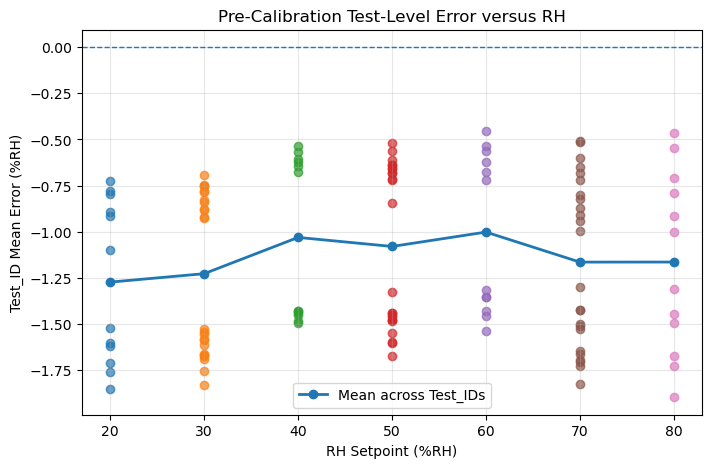

In [21]:
# ------------------------------------------------------------
# SC-05C: Test_ID mean error versus RH setpoint
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

for rh_value in sorted(test_summary_df["RH_Setpoint"].unique()):
    subset = test_summary_df.loc[
        test_summary_df["RH_Setpoint"] == rh_value,
        "Mean_Error_RH",
    ]

    ax.scatter(
        [rh_value] * len(subset),
        subset,
        alpha=0.7,
    )

ax.plot(
    rh_summary_df["RH_Setpoint"],
    rh_summary_df["Mean_Error_RH"],
    marker="o",
    linewidth=2,
    label="Mean across Test_IDs",
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel("RH Setpoint (%RH)")
ax.set_ylabel("Test_ID Mean Error (%RH)")
ax.set_title("Pre-Calibration Test-Level Error versus RH")
ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

In [22]:
# ------------------------------------------------------------
# SC-05D: Endpoint change across the tested RH range
# ------------------------------------------------------------

lowest_rh_row = rh_summary_df.iloc[0]
highest_rh_row = rh_summary_df.iloc[-1]

rh_endpoint_change = (
    highest_rh_row["Mean_Error_RH"]
    - lowest_rh_row["Mean_Error_RH"]
)

print(
    f"Lowest RH setpoint          : "
    f"{lowest_rh_row['RH_Setpoint']:.1f} %RH"
)

print(
    f"Mean error at lowest RH     : "
    f"{lowest_rh_row['Mean_Error_RH']:.4f} %RH"
)

print(
    f"Highest RH setpoint         : "
    f"{highest_rh_row['RH_Setpoint']:.1f} %RH"
)

print(
    f"Mean error at highest RH    : "
    f"{highest_rh_row['Mean_Error_RH']:.4f} %RH"
)

print(
    f"Endpoint error change       : "
    f"{rh_endpoint_change:.4f} %RH"
)

Lowest RH setpoint          : 20.0 %RH
Mean error at lowest RH     : -1.2729 %RH
Highest RH setpoint         : 80.0 %RH
Mean error at highest RH    : -1.1641 %RH
Endpoint error change       : 0.1087 %RH


In [23]:
# ------------------------------------------------------------
# SC-05E: RH-dependence analysis checks
# ------------------------------------------------------------

expected_rh_levels = {
    20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0
}

observed_rh_levels = set(
    rh_summary_df["RH_Setpoint"].tolist()
)

all_tests_accounted_for = (
    rh_summary_df["N_Test_IDs"].sum()
    == len(test_summary_df)
)

expected_levels_present = (
    observed_rh_levels == expected_rh_levels
)

no_missing_rh_metrics = (
    rh_summary_df[
        [
            "Mean_Error_RH",
            "Median_Error_RH",
            "Std_Error_RH",
            "MAE_RH",
        ]
    ]
    .notna()
    .all()
    .all()
)

sc05_rh_pass = (
    all_tests_accounted_for
    and expected_levels_present
    and no_missing_rh_metrics
)

print(
    f"All Test_IDs accounted for : "
    f"{all_tests_accounted_for}"
)

print(
    f"Expected RH levels present  : "
    f"{expected_levels_present}"
)

print(
    f"RH summary metrics complete : "
    f"{no_missing_rh_metrics}"
)

print(
    "\nSC-05 RH-analysis check      : "
    f"{'PASS' if sc05_rh_pass else 'FAIL'}"
)

if not sc05_rh_pass:
    raise RuntimeError(
        "SC-05 RH-dependence verification failed."
    )

All Test_IDs accounted for : True
Expected RH levels present  : True
RH summary metrics complete : True

SC-05 RH-analysis check      : PASS


### SC-05 Engineering Interpretation

The RH-dependence analysis passed all structural and completeness checks.

The Test_ID-level mean error varies across the tested RH range, but the
marginal RH trend is not monotonic. Therefore, the pre-calibration error
should not be modeled or interpreted as a simple linear function of RH based
on this analysis alone.

The individual Test_ID results also show two visually separated error bands
at most RH setpoints. This indicates that the variation attributed to RH in
the marginal summary may be strongly influenced by another experimental
factor, particularly direction.

The RH-level mean therefore represents an average across multiple test
conditions rather than an isolated RH effect. Temperature and direction must
be examined separately before attributing the observed variation to RH alone.

SC-05 establishes that the error is not well described by a single constant
offset across the entire RH range, but it does not yet isolate the physical
source of that variation.

The endpoint change from 20 to 80 %RH was only +0.1087 %RH, indicating little
net difference between the two range endpoints. However, the intermediate RH
levels show a non-monotonic pattern, so the small endpoint change should not
be interpreted as evidence that RH has negligible influence on the error.

**SC-05 decision: PASS**

## 10. Temperature Dependence

### SC-06 — Temperature Dependence of Pre-Calibration Error

SC-06 evaluates whether the pre-calibration DUT-reference error changes with
temperature.

The primary analysis remains at the Test_ID level.

Because RH and temperature are both experimental factors, temperature is not
evaluated only through a single marginal average. The analysis therefore
uses two complementary views:

1. a marginal summary across the three tested temperatures; and
2. an RH-preserving summary that compares temperature behavior separately
   at each RH setpoint.

This distinction is important because an overall temperature average may
hide condition-dependent behavior.

Direction, day, and run are not yet isolated in this section. Direction is
examined explicitly in SC-07.

In [24]:
# ------------------------------------------------------------
# SC-06A: Inspect Test_ID coverage across temperature levels
# ------------------------------------------------------------

temperature_test_counts = (
    test_summary_df
    .groupby("Temperature_Setpoint_C")
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
    )
    .reset_index()
    .sort_values("Temperature_Setpoint_C")
)

display(temperature_test_counts)

,Temperature_Setpoint_C,N_Test_IDs
0,15.0,40
1,25.0,40
2,35.0,40


In [25]:
# ------------------------------------------------------------
# SC-06B: Marginal Test_ID-level error summary by temperature
# ------------------------------------------------------------

temperature_summary_df = (
    test_summary_df
    .groupby("Temperature_Setpoint_C")
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        Mean_Error_RH=("Mean_Error_RH", "mean"),
        Median_Error_RH=("Mean_Error_RH", "median"),
        Std_Error_RH=("Mean_Error_RH", "std"),
        MAE_RH=("Mean_Error_RH", lambda x: x.abs().mean()),
        Min_Error_RH=("Mean_Error_RH", "min"),
        Max_Error_RH=("Mean_Error_RH", "max"),
    )
    .reset_index()
    .sort_values("Temperature_Setpoint_C")
)

display(temperature_summary_df.round(4))

,Temperature_Setpoint_C,N_Test_IDs,Mean_Error_RH,Median_Error_RH,Std_Error_RH,MAE_RH,Min_Error_RH,Max_Error_RH
0,15.0,40,-1.0899,-1.1993,0.4522,1.0899,-1.8527,-0.4557
1,25.0,40,-1.1363,-1.1387,0.4400,1.1363,-1.7615,-0.5625
2,35.0,40,-1.1974,-1.2148,0.4354,1.1974,-1.8967,-0.6200


In [26]:
# ------------------------------------------------------------
# SC-06C: Error summary by RH and temperature
# ------------------------------------------------------------

rh_temperature_summary_df = (
    test_summary_df
    .groupby(
        [
            "RH_Setpoint",
            "Temperature_Setpoint_C",
        ]
    )
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        Mean_Error_RH=("Mean_Error_RH", "mean"),
        Std_Error_RH=("Mean_Error_RH", "std"),
    )
    .reset_index()
    .sort_values(
        [
            "RH_Setpoint",
            "Temperature_Setpoint_C",
        ]
    )
)

display(rh_temperature_summary_df.round(4))

,RH_Setpoint,Temperature_Setpoint_C,N_Test_IDs,Mean_Error_RH,Std_Error_RH
0,20.0,15.0,4,-1.3937,0.4572
1,20.0,25.0,4,-1.2638,0.4982
2,20.0,35.0,4,-1.1611,0.4644
3,30.0,15.0,8,-1.2868,0.4400
4,30.0,25.0,8,-1.2193,0.4540
5,30.0,35.0,8,-1.1755,0.4453
6,40.0,15.0,4,-1.0249,0.4896
7,40.0,25.0,4,-1.0235,0.5074
8,40.0,35.0,4,-1.0436,0.4752
9,50.0,15.0,8,-1.0273,0.4352


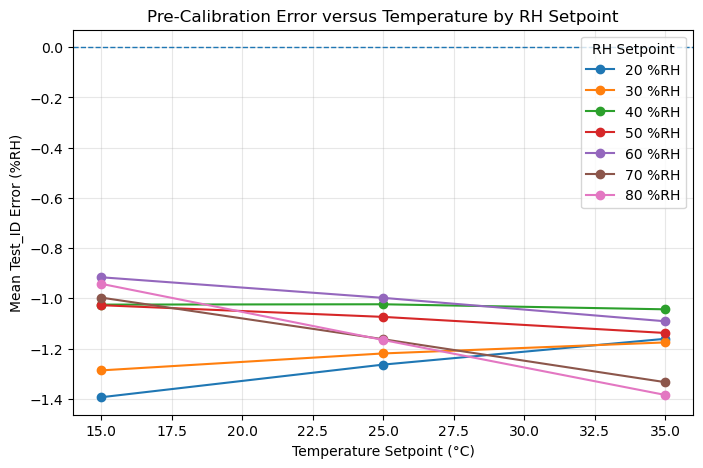

In [27]:
# ------------------------------------------------------------
# SC-06D: Temperature dependence while preserving RH context
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

for rh_value in sorted(
    rh_temperature_summary_df["RH_Setpoint"].unique()
):
    subset = (
        rh_temperature_summary_df.loc[
            rh_temperature_summary_df["RH_Setpoint"] == rh_value
        ]
        .sort_values("Temperature_Setpoint_C")
    )

    ax.plot(
        subset["Temperature_Setpoint_C"],
        subset["Mean_Error_RH"],
        marker="o",
        label=f"{rh_value:.0f} %RH",
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel("Temperature Setpoint (°C)")
ax.set_ylabel("Mean Test_ID Error (%RH)")
ax.set_title(
    "Pre-Calibration Error versus Temperature by RH Setpoint"
)

ax.grid(True, alpha=0.3)
ax.legend(title="RH Setpoint")

plt.show()

In [28]:
# ------------------------------------------------------------
# SC-06E: Endpoint temperature change at each RH
# ------------------------------------------------------------

temperature_endpoint_df = (
    rh_temperature_summary_df
    .pivot(
        index="RH_Setpoint",
        columns="Temperature_Setpoint_C",
        values="Mean_Error_RH",
    )
    .reset_index()
)

temperature_endpoint_df["Delta_Error_35_minus_15"] = (
    temperature_endpoint_df[35.0]
    - temperature_endpoint_df[15.0]
)

temperature_endpoint_df["Endpoint_Change_per_C"] = (
    temperature_endpoint_df["Delta_Error_35_minus_15"]
    / (35.0 - 15.0)
)

display(
    temperature_endpoint_df.round(4)
)

Temperature_Setpoint_C,RH_Setpoint,15.0,25.0,35.0,Delta_Error_35_minus_15,Endpoint_Change_per_C
0,20.0,-1.3937,-1.2638,-1.1611,0.2325,0.0116
1,30.0,-1.2868,-1.2193,-1.1755,0.1113,0.0056
2,40.0,-1.0249,-1.0235,-1.0436,-0.0188,-0.0009
3,50.0,-1.0273,-1.0738,-1.1378,-0.1105,-0.0055
4,60.0,-0.9161,-0.9980,-1.0912,-0.1751,-0.0088
5,70.0,-0.9971,-1.1628,-1.3336,-0.3365,-0.0168
6,80.0,-0.9422,-1.1657,-1.3844,-0.4422,-0.0221


In [29]:
# ------------------------------------------------------------
# SC-06F: Temperature-dependence analysis checks
# ------------------------------------------------------------

expected_temperature_levels = {
    15.0,
    25.0,
    35.0,
}

observed_temperature_levels = set(
    temperature_summary_df[
        "Temperature_Setpoint_C"
    ].tolist()
)

all_tests_accounted_for = (
    temperature_summary_df["N_Test_IDs"].sum()
    == len(test_summary_df)
)

expected_temperature_levels_present = (
    observed_temperature_levels
    == expected_temperature_levels
)

expected_rh_temperature_combinations = (
    len(
        test_summary_df[
            [
                "RH_Setpoint",
                "Temperature_Setpoint_C",
            ]
        ].drop_duplicates()
    )
)

actual_rh_temperature_combinations = (
    len(rh_temperature_summary_df)
)

rh_temperature_structure_complete = (
    actual_rh_temperature_combinations
    == expected_rh_temperature_combinations
)

no_missing_temperature_metrics = (
    rh_temperature_summary_df[
        [
            "Mean_Error_RH",
            "Std_Error_RH",
        ]
    ]
    .notna()
    .all()
    .all()
)

sc06_temperature_pass = (
    all_tests_accounted_for
    and expected_temperature_levels_present
    and rh_temperature_structure_complete
    and no_missing_temperature_metrics
)

print(
    f"All Test_IDs accounted for        : "
    f"{all_tests_accounted_for}"
)

print(
    f"Expected temperature levels       : "
    f"{expected_temperature_levels_present}"
)

print(
    f"RH × Temperature structure valid  : "
    f"{rh_temperature_structure_complete}"
)

print(
    f"Temperature metrics complete      : "
    f"{no_missing_temperature_metrics}"
)

print(
    "\nSC-06 temperature-analysis check   : "
    f"{'PASS' if sc06_temperature_pass else 'FAIL'}"
)

if not sc06_temperature_pass:
    raise RuntimeError(
        "SC-06 temperature-dependence verification failed."
    )

All Test_IDs accounted for        : True
Expected temperature levels       : True
RH × Temperature structure valid  : True
Temperature metrics complete      : True

SC-06 temperature-analysis check   : PASS


### SC-06 Engineering Interpretation

The SC-06 temperature-dependence analysis passed all structural and
completeness checks.

The marginal Test_ID-level mean error became more negative as temperature
increased, from approximately (-1.0899\ \%RH) at 15 °C to
(-1.1363\ \%RH) at 25 °C and (-1.1974\ \%RH) at 35 °C. However,
the RH-preserved analysis shows that this marginal trend does not represent
one universal temperature effect.

The 35 °C minus 15 °C endpoint change depended strongly on RH. It was
approximately (+0.2325\ \%RH) at 20 %RH and (+0.1113\ \%RH) at
30 %RH, was near zero at 40 %RH, and became increasingly negative at higher
RH, reaching approximately (-0.4422\ \%RH) at 80 %RH.

The change in both magnitude and sign indicates condition-dependent
temperature behavior and is consistent with an RH × Temperature interaction
structure. A formal interaction model is not estimated in this notebook, so
the result is interpreted as evidence that temperature cannot be represented
adequately by one global correction coefficient.

No calibration correction or specification-compliance decision is made in
this section.

**SC-06 decision: PASS**


## 11. Direction Dependence

### SC-07 — Matched UP/DOWN Direction Dependence

SC-07 evaluates whether the pre-calibration static DUT-reference error depends
on the direction of the RH transition.

Direction dependence is evaluated using matched test executions rather than
unmatched marginal averages.

A matched condition requires the following factors to remain identical:

- RH setpoint;
- temperature setpoint;
- day; and
- run.

The only intentionally different factor is `Direction`.

For each matched UP/DOWN pair, the direction difference is defined as:

$$
\Delta e_{\mathrm{dir}}
=
\overline{e}_{UP}
-
\overline{e}_{DOWN}
$$

where \(\overline{e}_{UP}\) and \(\overline{e}_{DOWN}\) are the Test_ID-level
mean DUT-reference errors for the matched UP and DOWN executions.

A negative value means that the UP-direction error is more negative than the
matched DOWN-direction error.

This analysis screens for static direction dependence. It is not yet treated
as a final hysteresis specification or compliance assessment.

In [30]:
# ------------------------------------------------------------
# SC-07A: Verify UP/DOWN matching structure
# ------------------------------------------------------------

match_keys = [
    "RH_Setpoint",
    "Temperature_Setpoint_C",
    "Day_ID",
    "Run_ID",
]

direction_structure_df = (
    test_summary_df
    .groupby(match_keys)
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        N_Directions=("Direction", "nunique"),
        Directions=(
            "Direction",
            lambda x: ", ".join(sorted(x.unique())),
        ),
    )
    .reset_index()
    .sort_values(match_keys)
)

display(direction_structure_df.head(20))

,RH_Setpoint,Temperature_Setpoint_C,Day_ID,Run_ID,N_Test_IDs,N_Directions,Directions
0,20.0,15.0,3,1,2,2,"DOWN, UP"
1,20.0,15.0,3,2,2,2,"DOWN, UP"
2,20.0,25.0,3,1,2,2,"DOWN, UP"
3,20.0,25.0,3,2,2,2,"DOWN, UP"
4,20.0,35.0,3,1,2,2,"DOWN, UP"
5,20.0,35.0,3,2,2,2,"DOWN, UP"
6,30.0,15.0,1,1,2,2,"DOWN, UP"
7,30.0,15.0,1,2,2,2,"DOWN, UP"
8,30.0,15.0,2,1,2,2,"DOWN, UP"
9,30.0,15.0,2,2,2,2,"DOWN, UP"


In [31]:
# ------------------------------------------------------------
# Check uniqueness within matched condition and direction
# ------------------------------------------------------------

direction_duplicate_check = (
    test_summary_df
    .groupby(match_keys + ["Direction"])
    .size()
    .reset_index(name="N_Test_IDs")
)

duplicate_direction_tests = direction_duplicate_check.loc[
    direction_duplicate_check["N_Test_IDs"] > 1
]

print(
    "Duplicate Test_ID groups within matched condition/direction : "
    f"{len(duplicate_direction_tests)}"
)

if len(duplicate_direction_tests) > 0:
    display(duplicate_direction_tests)

Duplicate Test_ID groups within matched condition/direction : 0


In [32]:
# ------------------------------------------------------------
# SC-07B: Create matched UP/DOWN Test_ID pairs
# ------------------------------------------------------------

up_df = (
    test_summary_df.loc[
        test_summary_df["Direction"] == "UP",
        match_keys + ["Test_ID", "Mean_Error_RH"],
    ]
    .rename(
        columns={
            "Test_ID": "Test_ID_UP",
            "Mean_Error_RH": "Mean_Error_UP",
        }
    )
)

down_df = (
    test_summary_df.loc[
        test_summary_df["Direction"] == "DOWN",
        match_keys + ["Test_ID", "Mean_Error_RH"],
    ]
    .rename(
        columns={
            "Test_ID": "Test_ID_DOWN",
            "Mean_Error_RH": "Mean_Error_DOWN",
        }
    )
)

direction_pairs_df = (
    up_df
    .merge(
        down_df,
        on=match_keys,
        how="outer",
        indicator=True,
    )
    .sort_values(match_keys)
)

print(
    direction_pairs_df["_merge"]
    .value_counts()
)

display(direction_pairs_df.head(10))

_merge
both          60
left_only      0
right_only     0
Name: count, dtype: int64


,RH_Setpoint,Temperature_Setpoint_C,Day_ID,Run_ID,Test_ID_UP,Mean_Error_UP,Test_ID_DOWN,Mean_Error_DOWN,_merge
0,20.0,15.0,3,1,ST-001,-1.708833,ST-003,-0.913500,both
1,20.0,15.0,3,2,ST-002,-1.852667,ST-004,-1.099667,both
2,20.0,25.0,3,1,ST-005,-1.619500,ST-007,-0.781000,both
3,20.0,25.0,3,2,ST-006,-1.761500,ST-008,-0.893167,both
4,20.0,35.0,3,1,ST-009,-1.522333,ST-011,-0.723667,both
5,20.0,35.0,3,2,ST-010,-1.600667,ST-012,-0.797833,both
6,30.0,15.0,1,1,ST-013,-1.611333,ST-017,-0.838000,both
7,30.0,15.0,1,2,ST-014,-1.672833,ST-018,-0.879500,both
8,30.0,15.0,2,1,ST-015,-1.663000,ST-019,-0.877500,both
9,30.0,15.0,2,2,ST-016,-1.827833,ST-020,-0.924167,both


In [33]:
# ------------------------------------------------------------
# SC-07C: Calculate matched direction differences
# ------------------------------------------------------------

matched_direction_df = (
    direction_pairs_df.loc[
        direction_pairs_df["_merge"] == "both"
    ]
    .drop(columns="_merge")
    .copy()
)

matched_direction_df["Direction_Difference_RH"] = (
    matched_direction_df["Mean_Error_UP"]
    - matched_direction_df["Mean_Error_DOWN"]
)

matched_direction_df["Abs_Direction_Difference_RH"] = (
    matched_direction_df["Direction_Difference_RH"].abs()
)

display(
    matched_direction_df.head(10).round(4)
)

,RH_Setpoint,Temperature_Setpoint_C,Day_ID,Run_ID,Test_ID_UP,Mean_Error_UP,Test_ID_DOWN,Mean_Error_DOWN,Direction_Difference_RH,Abs_Direction_Difference_RH
0,20.0,15.0,3,1,ST-001,-1.7088,ST-003,-0.9135,-0.7953,0.7953
1,20.0,15.0,3,2,ST-002,-1.8527,ST-004,-1.0997,-0.7530,0.7530
2,20.0,25.0,3,1,ST-005,-1.6195,ST-007,-0.7810,-0.8385,0.8385
3,20.0,25.0,3,2,ST-006,-1.7615,ST-008,-0.8932,-0.8683,0.8683
4,20.0,35.0,3,1,ST-009,-1.5223,ST-011,-0.7237,-0.7987,0.7987
5,20.0,35.0,3,2,ST-010,-1.6007,ST-012,-0.7978,-0.8028,0.8028
6,30.0,15.0,1,1,ST-013,-1.6113,ST-017,-0.8380,-0.7733,0.7733
7,30.0,15.0,1,2,ST-014,-1.6728,ST-018,-0.8795,-0.7933,0.7933
8,30.0,15.0,2,1,ST-015,-1.6630,ST-019,-0.8775,-0.7855,0.7855
9,30.0,15.0,2,2,ST-016,-1.8278,ST-020,-0.9242,-0.9037,0.9037


In [34]:
# ------------------------------------------------------------
# SC-07D: Overall matched-direction summary
# ------------------------------------------------------------

direction_difference = (
    matched_direction_df["Direction_Difference_RH"]
)

direction_metrics = {
    "N_Matched_Pairs": len(matched_direction_df),
    "Mean_Direction_Difference_RH": direction_difference.mean(),
    "Median_Direction_Difference_RH": direction_difference.median(),
    "Std_Direction_Difference_RH": direction_difference.std(ddof=1),
    "Mean_Abs_Direction_Difference_RH": (
        direction_difference.abs().mean()
    ),
    "Min_Direction_Difference_RH": direction_difference.min(),
    "Max_Direction_Difference_RH": direction_difference.max(),
    "Max_Abs_Direction_Difference_RH": (
        direction_difference.abs().max()
    ),
}

direction_metrics_df = pd.DataFrame([direction_metrics])

display(direction_metrics_df.round(4))

,N_Matched_Pairs,Mean_Direction_Difference_RH,Median_Direction_Difference_RH,Std_Direction_Difference_RH,Mean_Abs_Direction_Difference_RH,Min_Direction_Difference_RH,Max_Direction_Difference_RH,Max_Abs_Direction_Difference_RH
0,60,-0.8304,-0.8273,0.0469,0.8304,-0.925,-0.6985,0.925


In [35]:
# ------------------------------------------------------------
# SC-07E: Direction difference by RH setpoint
# ------------------------------------------------------------

direction_by_rh_df = (
    matched_direction_df
    .groupby("RH_Setpoint")
    .agg(
        N_Matched_Pairs=("Direction_Difference_RH", "size"),
        Mean_Direction_Difference_RH=(
            "Direction_Difference_RH",
            "mean",
        ),
        Median_Direction_Difference_RH=(
            "Direction_Difference_RH",
            "median",
        ),
        Std_Direction_Difference_RH=(
            "Direction_Difference_RH",
            "std",
        ),
        Mean_Abs_Direction_Difference_RH=(
            "Abs_Direction_Difference_RH",
            "mean",
        ),
    )
    .reset_index()
    .sort_values("RH_Setpoint")
)

display(direction_by_rh_df.round(4))

,RH_Setpoint,N_Matched_Pairs,Mean_Direction_Difference_RH,Median_Direction_Difference_RH,Std_Direction_Difference_RH,Mean_Abs_Direction_Difference_RH
0,20.0,6,-0.8094,-0.8007,0.0396,0.8094
1,30.0,12,-0.8250,-0.8178,0.0412,0.8250
2,40.0,6,-0.8470,-0.8497,0.0557,0.8470
3,50.0,12,-0.8375,-0.8337,0.0429,0.8375
4,60.0,6,-0.8127,-0.8168,0.0364,0.8127
5,70.0,12,-0.8278,-0.8257,0.0601,0.8278
6,80.0,6,-0.8546,-0.8656,0.0461,0.8546


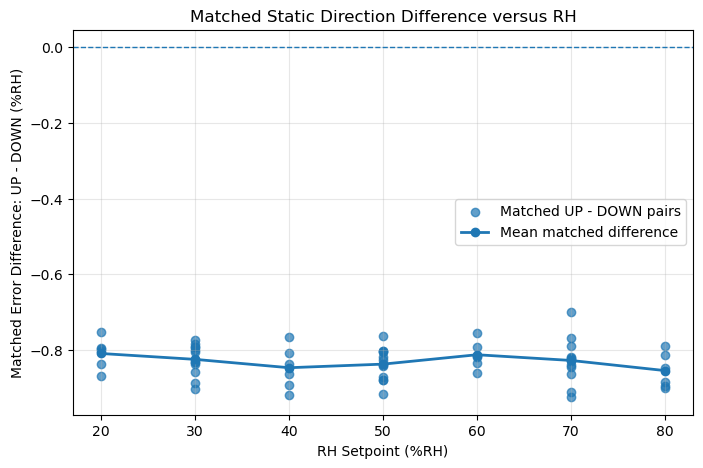

In [36]:
# ------------------------------------------------------------
# SC-07F: Matched direction difference versus RH
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    matched_direction_df["RH_Setpoint"],
    matched_direction_df["Direction_Difference_RH"],
    alpha=0.7,
    label="Matched UP - DOWN pairs",
)

ax.plot(
    direction_by_rh_df["RH_Setpoint"],
    direction_by_rh_df["Mean_Direction_Difference_RH"],
    marker="o",
    linewidth=2,
    label="Mean matched difference",
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel("RH Setpoint (%RH)")
ax.set_ylabel("Matched Error Difference: UP - DOWN (%RH)")
ax.set_title(
    "Matched Static Direction Difference versus RH"
)

ax.grid(True, alpha=0.3)
ax.legend()

plt.show()

In [37]:
# ------------------------------------------------------------
# SC-07G: Matched direction-analysis checks
# ------------------------------------------------------------

no_duplicate_direction_tests = (
    len(duplicate_direction_tests) == 0
)

all_direction_tests_matched = (
    direction_pairs_df["_merge"]
    .eq("both")
    .all()
)

has_matched_pairs = (
    len(matched_direction_df) > 0
)

pair_accounting_valid = (
    2 * len(matched_direction_df)
    == len(test_summary_df)
)

no_missing_direction_differences = (
    matched_direction_df[
        "Direction_Difference_RH"
    ]
    .notna()
    .all()
)

sc07_direction_pass = (
    no_duplicate_direction_tests
    and all_direction_tests_matched
    and has_matched_pairs
    and pair_accounting_valid
    and no_missing_direction_differences
)

print(
    f"No duplicate direction tests : "
    f"{no_duplicate_direction_tests}"
)

print(
    f"All UP/DOWN tests matched    : "
    f"{all_direction_tests_matched}"
)

print(
    f"Matched pairs available      : "
    f"{has_matched_pairs}"
)

print(
    f"Pair accounting valid        : "
    f"{pair_accounting_valid}"
)

print(
    f"Direction differences valid  : "
    f"{no_missing_direction_differences}"
)

print(
    "\nSC-07 direction-analysis check : "
    f"{'PASS' if sc07_direction_pass else 'FAIL'}"
)

if not sc07_direction_pass:
    raise RuntimeError(
        "SC-07 matched-direction verification failed."
    )

No duplicate direction tests : True
All UP/DOWN tests matched    : True
Matched pairs available      : True
Pair accounting valid        : True
Direction differences valid  : True

SC-07 direction-analysis check : PASS


### SC-07 Engineering Interpretation

The matched-direction analysis passed all structural and pairing checks.
All 120 direction-specific Test_IDs formed 60 complete matched UP/DOWN pairs,
with RH, temperature, day, and run held constant within each pair.

The mean matched direction difference was approximately
(-0.8304\ \%RH), with a median of (-0.8273\ \%RH) and a standard
deviation of (0.0469\ \%RH). All matched differences were negative,
ranging from approximately (-0.9250\ \%RH) to (-0.6985\ \%RH).

The negative sign means that the UP-direction error was consistently more
negative than the matched DOWN-direction error. The RH-specific mean matched
differences were also negative at every tested RH level, ranging from about
(-0.8094\ \%RH) to (-0.8546\ \%RH).

These results provide strong evidence of persistent static direction
dependence across the characterization range. Because the comparison is
matched on RH, temperature, day, and run, the observed separation is much
less likely to be an artifact of those factors.

This result is treated as static direction-dependence / hysteresis screening,
not as a final hysteresis specification-compliance determination.

**SC-07 decision: PASS**


## 12. Day / Run Context

### SC-08 — Day and Run Contextual Inspection

SC-08 examines whether the Test_ID-level pre-calibration errors show obvious
structure across test days or run identifiers.

This section is intentionally descriptive. It does not perform a formal
repeatability and reproducibility variance decomposition.

Day and run are treated as test-organization and replication factors rather
than physical operating conditions such as RH or temperature.

The purpose of this inspection is to identify whether test-to-test error
variation appears to contain a noticeable day or run component that should
be investigated more formally in the dedicated repeatability and
reproducibility analysis.

In [38]:
# ------------------------------------------------------------
# SC-08A: Inspect Day × Run Test_ID coverage
# ------------------------------------------------------------

day_run_coverage_df = (
    test_summary_df
    .groupby(
        [
            "Day_ID",
            "Run_ID",
        ]
    )
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
    )
    .reset_index()
    .sort_values(
        [
            "Day_ID",
            "Run_ID",
        ]
    )
)

display(day_run_coverage_df)

,Day_ID,Run_ID,N_Test_IDs
0,1,1,18
1,1,2,18
2,2,1,18
3,2,2,18
4,3,1,24
5,3,2,24


In [39]:
# ------------------------------------------------------------
# SC-08B: Test_ID-level error summary by day
# ------------------------------------------------------------

day_summary_df = (
    test_summary_df
    .groupby("Day_ID")
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        Mean_Error_RH=("Mean_Error_RH", "mean"),
        Median_Error_RH=("Mean_Error_RH", "median"),
        Std_Error_RH=("Mean_Error_RH", "std"),
        Min_Error_RH=("Mean_Error_RH", "min"),
        Max_Error_RH=("Mean_Error_RH", "max"),
    )
    .reset_index()
    .sort_values("Day_ID")
)

display(day_summary_df.round(4))

,Day_ID,N_Test_IDs,Mean_Error_RH,Median_Error_RH,Std_Error_RH,Min_Error_RH,Max_Error_RH
0,1,36,-1.1120,-1.1030,0.4318,-1.7288,-0.5085
1,2,36,-1.2022,-1.2083,0.4432,-1.8278,-0.6017
2,3,48,-1.1174,-1.2062,0.4510,-1.8967,-0.4557


In [40]:
# ------------------------------------------------------------
# SC-08C: Test_ID-level error summary by run
# ------------------------------------------------------------

run_summary_df = (
    test_summary_df
    .groupby("Run_ID")
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        Mean_Error_RH=("Mean_Error_RH", "mean"),
        Median_Error_RH=("Mean_Error_RH", "median"),
        Std_Error_RH=("Mean_Error_RH", "std"),
        Min_Error_RH=("Mean_Error_RH", "min"),
        Max_Error_RH=("Mean_Error_RH", "max"),
    )
    .reset_index()
    .sort_values("Run_ID")
)

display(run_summary_df.round(4))

,Run_ID,N_Test_IDs,Mean_Error_RH,Median_Error_RH,Std_Error_RH,Min_Error_RH,Max_Error_RH
0,1,60,-1.0986,-1.1196,0.4377,-1.7255,-0.4557
1,2,60,-1.1838,-1.2278,0.4440,-1.8967,-0.5148


In [41]:
# ------------------------------------------------------------
# SC-08D: Day × Run contextual summary
# ------------------------------------------------------------

day_run_summary_df = (
    test_summary_df
    .groupby(
        [
            "Day_ID",
            "Run_ID",
        ]
    )
    .agg(
        N_Test_IDs=("Test_ID", "nunique"),
        Mean_Error_RH=("Mean_Error_RH", "mean"),
        Median_Error_RH=("Mean_Error_RH", "median"),
        Std_Error_RH=("Mean_Error_RH", "std"),
    )
    .reset_index()
    .sort_values(
        [
            "Day_ID",
            "Run_ID",
        ]
    )
)

display(day_run_summary_df.round(4))

,Day_ID,Run_ID,N_Test_IDs,Mean_Error_RH,Median_Error_RH,Std_Error_RH
0,1,1,18,-1.0787,-1.0852,0.4392
1,1,2,18,-1.1453,-1.1660,0.4342
2,2,1,18,-1.1551,-1.1809,0.4470
3,2,2,18,-1.2493,-1.2375,0.4472
4,3,1,24,-1.0713,-1.1132,0.4444
5,3,2,24,-1.1634,-1.2278,0.4622


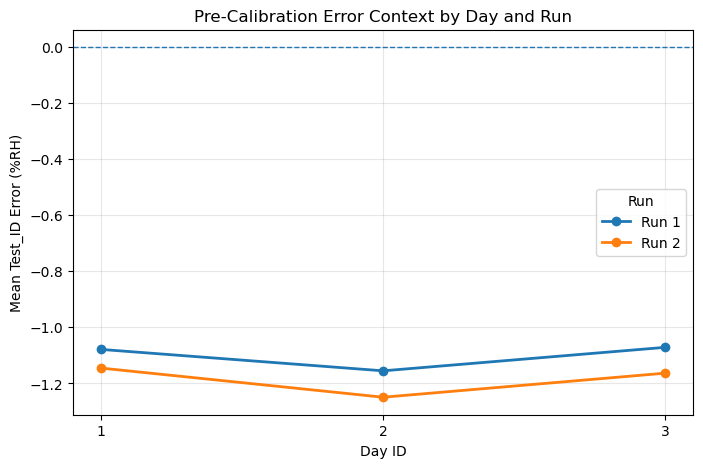

In [42]:
# ------------------------------------------------------------
# SC-08E: Mean error by day and run
# ------------------------------------------------------------

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

for run_value in sorted(
    day_run_summary_df["Run_ID"].unique()
):
    subset = (
        day_run_summary_df.loc[
            day_run_summary_df["Run_ID"] == run_value
        ]
        .sort_values("Day_ID")
    )

    ax.plot(
        subset["Day_ID"],
        subset["Mean_Error_RH"],
        marker="o",
        linewidth=2,
        label=f"Run {run_value}",
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel("Day ID")
ax.set_ylabel("Mean Test_ID Error (%RH)")
ax.set_title(
    "Pre-Calibration Error Context by Day and Run"
)

ax.set_xticks(
    sorted(day_run_summary_df["Day_ID"].unique())
)

ax.grid(True, alpha=0.3)
ax.legend(title="Run")

plt.show()

In [43]:
# ------------------------------------------------------------
# SC-08F: Day / Run contextual-analysis checks
# ------------------------------------------------------------

expected_days = {
    1,
    2,
    3,
}

expected_runs = {
    1,
    2,
}

observed_days = set(
    test_summary_df["Day_ID"].unique()
)

observed_runs = set(
    test_summary_df["Run_ID"].unique()
)

expected_days_present = (
    observed_days == expected_days
)

expected_runs_present = (
    observed_runs == expected_runs
)

all_tests_accounted_for_by_day = (
    day_summary_df["N_Test_IDs"].sum()
    == len(test_summary_df)
)

all_tests_accounted_for_by_run = (
    run_summary_df["N_Test_IDs"].sum()
    == len(test_summary_df)
)

no_missing_day_run_metrics = (
    day_run_summary_df[
        [
            "Mean_Error_RH",
            "Median_Error_RH",
            "Std_Error_RH",
        ]
    ]
    .notna()
    .all()
    .all()
)

sc08_day_run_pass = (
    expected_days_present
    and expected_runs_present
    and all_tests_accounted_for_by_day
    and all_tests_accounted_for_by_run
    and no_missing_day_run_metrics
)

print(
    f"Expected days present           : "
    f"{expected_days_present}"
)

print(
    f"Expected runs present           : "
    f"{expected_runs_present}"
)

print(
    f"All tests accounted for by day : "
    f"{all_tests_accounted_for_by_day}"
)

print(
    f"All tests accounted for by run : "
    f"{all_tests_accounted_for_by_run}"
)

print(
    f"Day/run metrics complete        : "
    f"{no_missing_day_run_metrics}"
)

print(
    "\nSC-08 day/run-context check      : "
    f"{'PASS' if sc08_day_run_pass else 'FAIL'}"
)

if not sc08_day_run_pass:
    raise RuntimeError(
        "SC-08 day/run contextual verification failed."
    )

Expected days present           : True
Expected runs present           : True
All tests accounted for by day : True
All tests accounted for by run : True
Day/run metrics complete        : True

SC-08 day/run-context check      : PASS


### SC-08 Engineering Interpretation

The day/run contextual analysis passed all structural and completeness checks.

The marginal mean Test_ID error was approximately -1.1120 %RH on Day 1,
-1.2022 %RH on Day 2, and -1.1174 %RH on Day 3. Day 2 therefore showed a
somewhat more negative average error, while Days 1 and 3 were similar.

The day-level comparison should be interpreted cautiously because the number
of characterization Test_IDs was not identical across days: Days 1 and 2
contained 36 Test_IDs each, whereas Day 3 contained 48. The marginal day
means may therefore reflect differences in the mix of experimental
conditions as well as possible day-related behavior.

The run comparison showed a more consistent pattern. Run 1 had an overall
mean error of -1.0986 %RH, whereas Run 2 had an overall mean error of
-1.1838 %RH, corresponding to an overall shift of approximately -0.0852 %RH.

The same ordering was observed within all three days: Run 2 was more negative
than Run 1 on Day 1, Day 2, and Day 3. This provides evidence of a small but
consistent run-related shift in the characterization results.

The error standard deviations remained broadly similar across days and runs,
suggesting that the observed contextual differences are more strongly
associated with shifts in the center of the error distribution than with
large changes in scatter.

These observations are descriptive only. No formal repeatability,
reproducibility, or variance-component estimate is assigned in SC-08.
Those effects are deferred to the dedicated R&R analysis.

**SC-08 decision: PASS**


## 13. Results Summary

### SC-09 — Static Characterization Results Synthesis

This section consolidates the principal pre-calibration findings from the
completed static-characterization analyses.

The purpose is not to introduce new analysis, but to provide a traceable
summary of the numerical evidence established in SC-04 through SC-08.

The summary includes:

- the overall pre-calibration error baseline;
- RH-dependent behavior;
- temperature-dependent behavior;
- matched direction dependence;
- and day/run contextual structure.

All results remain descriptive of the pre-calibration characterization
dataset. No calibration correction, formal R&R decomposition, uncertainty
budget, or final specification-compliance decision is introduced here.

In [44]:
# ------------------------------------------------------------
# SC-09A: Consolidate principal static-characterization results
# ------------------------------------------------------------

# Overall Test_ID-level baseline
overall_mbe = test_metrics["MBE_RH"]
overall_mae = test_metrics["MAE_RH"]
overall_rmse = test_metrics["RMSE_RH"]
overall_std = test_metrics["Std_Error_RH"]

# RH endpoint comparison
rh_low = lowest_rh_row["RH_Setpoint"]
rh_high = highest_rh_row["RH_Setpoint"]
rh_low_error = lowest_rh_row["Mean_Error_RH"]
rh_high_error = highest_rh_row["Mean_Error_RH"]

# Temperature endpoint behavior across RH
temp_change_min = (
    temperature_endpoint_df["Delta_Error_35_minus_15"].min()
)

temp_change_max = (
    temperature_endpoint_df["Delta_Error_35_minus_15"].max()
)

# Matched direction behavior
mean_direction_difference = (
    direction_metrics["Mean_Direction_Difference_RH"]
)

mean_abs_direction_difference = (
    direction_metrics["Mean_Abs_Direction_Difference_RH"]
)

# Run contextual shift
run1_mean = (
    run_summary_df.loc[
        run_summary_df["Run_ID"] == 1,
        "Mean_Error_RH",
    ].iloc[0]
)

run2_mean = (
    run_summary_df.loc[
        run_summary_df["Run_ID"] == 2,
        "Mean_Error_RH",
    ].iloc[0]
)

run2_minus_run1 = run2_mean - run1_mean

results_summary_df = pd.DataFrame(
    [
        {
            "Finding": "Overall Test_ID-level MBE",
            "Value": overall_mbe,
            "Unit": "%RH",
        },
        {
            "Finding": "Overall Test_ID-level MAE",
            "Value": overall_mae,
            "Unit": "%RH",
        },
        {
            "Finding": "Overall Test_ID-level RMSE",
            "Value": overall_rmse,
            "Unit": "%RH",
        },
        {
            "Finding": "Overall Test_ID-level error SD",
            "Value": overall_std,
            "Unit": "%RH",
        },
        {
            "Finding": f"Mean error at {rh_low:.0f} %RH",
            "Value": rh_low_error,
            "Unit": "%RH",
        },
        {
            "Finding": f"Mean error at {rh_high:.0f} %RH",
            "Value": rh_high_error,
            "Unit": "%RH",
        },
        {
            "Finding": "RH endpoint error change",
            "Value": rh_endpoint_change,
            "Unit": "%RH",
        },
        {
            "Finding": "Minimum 35°C - 15°C error change across RH",
            "Value": temp_change_min,
            "Unit": "%RH",
        },
        {
            "Finding": "Maximum 35°C - 15°C error change across RH",
            "Value": temp_change_max,
            "Unit": "%RH",
        },
        {
            "Finding": "Mean matched UP - DOWN difference",
            "Value": mean_direction_difference,
            "Unit": "%RH",
        },
        {
            "Finding": "Mean absolute UP - DOWN difference",
            "Value": mean_abs_direction_difference,
            "Unit": "%RH",
        },
        {
            "Finding": "Run 2 - Run 1 mean-error shift",
            "Value": run2_minus_run1,
            "Unit": "%RH",
        },
    ]
)

display(results_summary_df.round(4))

,Finding,Value,Unit
0,Overall Test_ID-level MBE,-1.1412,%RH
1,Overall Test_ID-level MAE,1.1412,%RH
2,Overall Test_ID-level RMSE,1.2228,%RH
3,Overall Test_ID-level error SD,0.4411,%RH
4,Mean error at 20 %RH,-1.2729,%RH
5,Mean error at 80 %RH,-1.1641,%RH
6,RH endpoint error change,0.1087,%RH
7,Minimum 35°C - 15°C error change across RH,-0.4422,%RH
8,Maximum 35°C - 15°C error change across RH,0.2325,%RH
9,Mean matched UP - DOWN difference,-0.8304,%RH


In [45]:
# ------------------------------------------------------------
# SC-09B: Results-summary integrity check
# ------------------------------------------------------------

summary_values_complete = (
    results_summary_df["Value"]
    .notna()
    .all()
)

expected_summary_rows = (
    len(results_summary_df) == 12
)

sc09_summary_pass = (
    summary_values_complete
    and expected_summary_rows
)

print(
    f"Summary values complete : "
    f"{summary_values_complete}"
)

print(
    f"Expected summary rows    : "
    f"{expected_summary_rows}"
)

print(
    "\nSC-09 results-summary check : "
    f"{'PASS' if sc09_summary_pass else 'FAIL'}"
)

if not sc09_summary_pass:
    raise RuntimeError(
        "SC-09 results-summary verification failed."
    )

Summary values complete : True
Expected summary rows    : True

SC-09 results-summary check : PASS


## 14. Engineering Interpretation

The pre-calibration static characterization demonstrates that the DUT does
not exhibit a simple constant-offset error.

Across the 120 characterization Test_IDs, the overall mean error was
approximately \(-1.1412\ \%RH\), with an MAE of \(1.1412\ \%RH\), an RMSE
of \(1.2228\ \%RH\), and a Test_ID-level error standard deviation of
\(0.4411\ \%RH\). All Test_ID-level mean errors were negative, indicating a
persistent tendency for the DUT to read lower than the reference throughout
the characterization campaign.

The overall negative error is therefore not the result of cancellation
between positive and negative test-level errors. However, the error magnitude
varies substantially across test conditions, so the DUT behavior should not
be represented as a single fixed bias.

The RH analysis showed only a small net endpoint change of approximately
\(+0.1087\ \%RH\) between 20 and 80 %RH. Nevertheless, the intermediate RH
levels showed non-monotonic structure. Therefore, the small endpoint
difference does not imply that RH has negligible influence on the
measurement error.

Temperature effects were also condition dependent. The change in mean error
between 15 and 35 °C ranged from approximately \(-0.4422\ \%RH\) to
\(+0.2325\ \%RH\) across the tested RH levels. The change in both magnitude
and sign indicates that a single global temperature correction would not
adequately describe the observed behavior. The results suggest that
temperature response should be interpreted together with RH rather than as
an isolated factor.

The strongest static structure identified in this notebook was associated
with direction. Matched UP/DOWN comparisons produced a mean direction
difference of approximately \(-0.8304\ \%RH\). Because RH, temperature, day,
and run were held matched in these comparisons, the result provides strong
evidence of static direction-dependent behavior. The UP-direction tests
produced substantially more negative errors than the matched DOWN-direction
tests.

Day/run inspection identified a smaller contextual effect. Run 2 showed an
overall mean-error shift of approximately \(-0.0851\ \%RH\) relative to
Run 1, and the same ordering was observed across all three test days.
This effect is much smaller than the matched direction difference and is
reserved for formal variance-component analysis in the dedicated R&R stage.

Overall, the DUT exhibits a persistent negative systematic tendency combined
with condition-dependent structure. Direction is a major contributor to the
observed static variation, while RH and temperature effects cannot be
interpreted independently without preserving their experimental context.

These findings establish the pre-calibration measurement baseline required
for later calibration development. No calibration correction, uncertainty
budget, or final specification-compliance decision is made in this notebook.

## 15. What I Learned

This milestone clarified several important principles of static sensor
characterization.

First, repeated measurement samples and independent test executions must be
treated differently. The 60 samples collected within one Test_ID describe
short-term behavior during a single test execution; they are not 60
independent experiments. For condition-level analysis, the Test_ID is the
appropriate experimental unit.

Second, measurement error must be defined explicitly and consistently. In
this project,

$$
Error_{RH} = RH_{DUT} - RH_{Reference}
$$

so a negative value means that the DUT reads lower than the reference.
Maintaining a fixed sign convention is necessary for correct interpretation
of bias, direction dependence, and calibration behavior.

Third, bias and scatter describe different characteristics of measurement
performance. A sensor may show a persistent systematic tendency while still
having relatively low short-term scatter. Therefore, mean error alone is not
sufficient to characterize measurement quality.

Fourth, an overall average can hide important condition-dependent behavior.
The overall Test_ID-level mean error was approximately \(-1.14\ \%RH\), but
the static error was not adequately described by a single constant offset.
RH, temperature, direction, and test context all contributed structure to the
observed results.

Fifth, matched comparisons are more informative than simple marginal
comparisons when isolating a factor effect. Matching RH, temperature, day, and
run before comparing UP and DOWN directions revealed a strong
direction-dependent effect that would have been less clearly interpreted from
overall averages alone.

Sixth, data preparation is part of the measurement methodology rather than a
separate administrative task. Role isolation, Test_ID integrity checks,
sample-count verification, outlier-handling policy, and prevention of
calibration/validation leakage were required before the performance analysis
could be considered defensible.

Finally, characterization should precede calibration. The purpose of static
characterization is to understand the structure of the measurement error
before selecting a correction model. Calibration should respond to observed
sensor behavior rather than assume in advance that the error is a simple
constant offset.

## 16. Key Metrology Concepts

The following concepts are central to the interpretation of this static
characterization study.

### Measurand

The **measurand** is the quantity intended to be measured.

In this study, the principal measurand is relative humidity, expressed in
percent relative humidity (%RH).

---

### DUT — Device Under Test

The **Device Under Test (DUT)** is the sensor whose measurement behavior is
being characterized.

Its indication is represented by:

$$
RH_{DUT}
$$

---

### Reference Indication

The **reference indication** is the RH value reported by the reference
measurement system.

It is represented by:

$$
RH_{Reference}
$$

The reference is not treated as exact physical truth. It has its own
measurement uncertainty.

---

### Setpoint

A **setpoint** is the commanded target condition applied to the environmental
chamber.

For example:

$$
RH_{setpoint} = 50\ \%RH
$$

does not imply that the actual reference indication is exactly 50 %RH.

Therefore:

$$
\text{Chamber Setpoint}
\neq
\text{Reference Indication}
$$

---

### Measurement Error

The observed RH error is defined as:

$$
e = RH_{DUT} - RH_{Reference}
$$

A positive error means that the DUT reads high relative to the reference.

A negative error means that the DUT reads low relative to the reference.

---

### Bias / Systematic Tendency

A persistent non-zero mean error provides evidence of a **systematic
measurement tendency**.

In this notebook, MBE is used to estimate the directional tendency of the
DUT-reference error.

A non-zero MBE should not automatically be interpreted as an exact
systematic error because the reference system also has uncertainty and the
error may depend on operating conditions.

---

### Scatter

**Scatter** describes the spread of repeated measurement results around their
central value.

Low scatter indicates that repeated measurements remain relatively close
together.

Bias and scatter describe different properties:

$$
\text{Bias} \rightarrow \text{location of the error distribution}
$$

$$
\text{Scatter} \rightarrow \text{spread of the error distribution}
$$

A DUT can therefore be repeatable but still biased.

---

### Sample

A **sample** is one measurement record acquired at one sampling instant.

In the characterization dataset, each Test_ID contains 60 repeated samples.

These samples describe short-term behavior within one test execution.

---

### Test_ID

A **Test_ID** identifies one traceable test execution performed under a
defined experimental condition.

For condition-level analysis, the Test_ID is treated as the primary
experimental unit.

---

### Experimental Unit

The **experimental unit** is the smallest unit that can be treated as an
independent execution of the experiment for the analysis of interest.

In this static characterization study, the Test_ID is the primary
experimental unit for comparing test conditions.

---

### Pseudoreplication

**Pseudoreplication** occurs when repeated observations that are not
independent experiments are incorrectly treated as independent experimental
replicates.

Treating the 60 samples within one Test_ID as 60 independent experiments
would artificially inflate the apparent amount of independent evidence.

---

### Test Condition

A **test condition** is defined by the relevant combination of experimental
factor levels.

Examples include:

- RH setpoint;
- temperature setpoint;
- direction;
- day;
- run; and
- chamber state.

---

### Matched Condition

Two tests are considered **matched** when the relevant experimental factors
are held the same except for the factor intentionally being compared.

For the direction analysis, matched UP/DOWN pairs had the same:

- RH setpoint;
- temperature setpoint;
- day; and
- run.

Only direction was intentionally different.

---

### Direction Dependence

**Direction dependence** occurs when the DUT response differs depending on
whether the environmental quantity is approached from an increasing or
decreasing direction.

In this notebook, direction dependence is evaluated using matched UP/DOWN
comparisons.

The analysis is treated as a static hysteresis screening rather than a final
hysteresis compliance determination.

---

### Marginal Effect

A **marginal effect** is obtained when one factor is summarized while
averaging over other experimental factors.

For example, an RH-level mean error may also contain contributions from
temperature, direction, day, or run.

Therefore, a marginal trend should not automatically be interpreted as an
isolated factor effect.

---

### Interaction

An **interaction** occurs when the effect of one factor depends on the level
of another factor.

For example, if the temperature-induced error change differs across RH
levels, this suggests possible:

$$
RH \times Temperature
$$

interaction.

---

### Pre-Calibration Baseline

The **pre-calibration baseline** describes the DUT measurement behavior before
any correction model is fitted.

This baseline provides the reference point against which later calibration
and validation performance can be compared.

---

### Traceability

**Traceability** in the dataset means that each measurement record can be
linked back to its test execution and experimental condition through
identifiers and metadata such as Test_ID, RH setpoint, temperature,
direction, day, and run.

---

### Data Leakage

**Data leakage** occurs when information reserved for later modeling or
validation improperly influences an earlier analysis stage.

In HV-004:

- CHARACTERIZATION data are used for static characterization;
- CALIBRATION data are reserved for model development;
- VALIDATION data remain independent until the calibration model is frozen.

This separation preserves the integrity of later validation.

## 17. Questions I Should Be Able to Answer

The following questions are used as a technical self-check for the static
characterization milestone.

1. What is the measurand in this study, and what is the DUT?

2. What is the difference between the chamber setpoint, the reference
   indication, and the DUT indication?

3. Why is the reference indication not treated as exact physical truth?

4. How is RH measurement error defined in this project?

$$
Error_{RH} = RH_{DUT} - RH_{Reference}
$$

5. What does a positive error mean? What does a negative error mean?

6. What is the difference between a measurement sample and a Test_ID?

7. Why are the 60 samples within one Test_ID not treated as 60 independent
   experiments?

8. What is pseudoreplication, and how was it avoided in this notebook?

9. Why was the Test_ID used as the primary experimental unit for
   condition-level characterization?

10. What is the difference between bias and scatter?

11. How can a sensor be repeatable but still biased?

12. What do MBE, MAE, RMSE, and standard deviation each tell us about
    measurement performance?

13. Why can a small MBE be misleading when positive and negative errors
    cancel?

14. Why was the DUT error not modeled as a single constant offset even though
    the overall Test_ID-level MBE was approximately -1.14 %RH?

15. Why is a small endpoint difference between 20 and 80 %RH not sufficient
    evidence that RH has little effect on sensor error?

16. Why was temperature analyzed while preserving RH context instead of using
    only a marginal temperature average?

17. What does an RH × Temperature interaction mean physically and
    statistically?

18. What is a matched condition, and why is matching important when comparing
    UP and DOWN directions?

19. How was the matched direction difference defined?

$$
\Delta e_{\mathrm{dir}}
=
\overline{e}_{UP}
-
\overline{e}_{DOWN}
$$

20. What does a negative matched UP-DOWN difference mean?

21. Why is the direction analysis described as static direction dependence or
    hysteresis screening rather than a final hysteresis compliance result?

22. What did the day/run analysis reveal, and why was formal R&R analysis
    deferred?

23. What is the difference between a shift in the center of an error
    distribution and a change in its scatter?

24. Why were calibration and validation observations excluded from this
    characterization notebook?

25. What is data leakage, and how was it prevented?

26. Why were statistically extreme observations not automatically removed as
    outliers?

27. What engineering evidence would justify excluding a measurement record?

28. Why should characterization be completed before calibration-model
    development?

29. What are the principal limitations of the conclusions from this notebook?

30. What additional analyses are required before making a final sensor
    compliance decision?

## 18. Connection to the Uncertainty Budget

The static-characterization results provide evidence that will later support
the measurement-uncertainty model, but the quantities identified in this
notebook should not all be inserted directly into the uncertainty budget.

A measurement-uncertainty budget is based on a defined measurement model and
the uncertainty associated with the quantities and corrections used in that
model.

The static-characterization stage therefore serves two purposes:

1. identify systematic and condition-dependent behavior that may require
   correction or explicit modeling; and
2. identify sources of residual variability that may contribute to the final
   uncertainty budget.

### Reference-System Uncertainty

The DUT error is calculated relative to a reference measurement system:

$$
e = RH_{DUT} - RH_{Reference}
$$

Because the reference indication is not exact physical truth, the uncertainty
associated with the reference system will contribute directly to the final
measurement uncertainty.

The reference uncertainty is not estimated in this notebook; it will be
incorporated later using the documented reference-system specification and
uncertainty information.

### Repeatability and Short-Term Variation

The repeated samples within each Test_ID contain information about short-term
measurement scatter.

The within-test standard deviation may contribute to a Type A uncertainty
evaluation, depending on the final measurand and reporting model.

However, the appropriate uncertainty of an individual reading is different
from the uncertainty of an average based on multiple repeated readings.
Therefore, the final treatment of repeatability depends on the defined
measurement result.

### Test-to-Test and Run-to-Run Variation

The characterization results show variation among Test_ID means and a small,
consistent Run 2 versus Run 1 shift.

These observations indicate that test-to-test and run-related effects may
contribute to measurement variability.

Formal separation of repeatability and reproducibility components is deferred
to the dedicated R&R analysis before any such component is entered into the
uncertainty budget.

### RH-Dependent Behavior

The DUT error varies across the tested RH range and is not adequately
described by a single constant offset.

This behavior does not automatically become one uncertainty component.
Instead, it may require an RH-dependent correction model.

The uncertainty budget should then account for the uncertainty associated
with the correction model and any residual RH-dependent error remaining after
calibration.

### Temperature-Dependent Behavior

The temperature analysis showed condition-dependent changes in error across
RH levels.

Because the observed temperature response is not described by one global
temperature coefficient, temperature should be included explicitly in the
measurement model or calibration strategy if it remains practically
significant.

Any residual temperature sensitivity after correction may contribute to the
final uncertainty budget.

### Direction Dependence

Matched UP/DOWN comparisons revealed substantial static direction-dependent
behavior.

This effect should not be inserted directly into the uncertainty budget as a
single standard uncertainty without first deciding how direction is handled
in the measurement procedure and calibration model.

Possible treatments include:

- controlling and specifying the measurement direction;
- applying a direction-dependent correction;
- treating direction as a modeled influence quantity; or
- including residual direction-dependent variation as an uncertainty
  contribution when the direction cannot be controlled or corrected.

The final treatment will depend on the intended measurement procedure.

### Resolution and Quantization

Instrument resolution is not evaluated numerically in this notebook, but it
is a separate uncertainty source that will be included in the final
uncertainty model.

For a digital resolution step \(\Delta\), a rectangular quantization model
may be represented by:

$$
u_{res} = \frac{\Delta}{\sqrt{12}}
$$

when the assumptions of the quantization model are appropriate.

### Combined Standard Uncertainty

After the measurement model and relevant uncertainty components are defined,
the combined standard uncertainty will be evaluated conceptually as:

$$
u_c^2(y)
=
\sum_i c_i^2 u_i^2
+
2\sum_{i<j} c_i c_j
\operatorname{Cov}(x_i,x_j)
$$

where \(u_i\) are standard uncertainties and \(c_i\) are sensitivity
coefficients.

The current notebook does not calculate the final combined uncertainty.
Instead, it identifies measurement behavior that must be understood before a
defensible uncertainty model can be constructed.

### Static-Characterization Contribution to the Uncertainty Model

The principal contributions of HV-004 to the later uncertainty analysis are:

- evidence of persistent DUT-reference bias;
- short-term within-test scatter;
- test-to-test variability;
- RH-dependent error structure;
- temperature-dependent behavior;
- matched direction dependence; and
- run-related contextual variation.

These results help determine which effects should be corrected, controlled,
modeled, or represented as residual uncertainty in the final measurement
model.

## 19. Final Engineering Takeaway

The static-characterization stage established that the DUT exhibits a
persistent negative pre-calibration error relative to the reference system,
with an overall Test_ID-level mean error of approximately \(-1.14\ \%RH\).

However, the DUT behavior is not adequately described by a single constant
offset.

The characterization results revealed additional condition-dependent
structure, including:

- non-monotonic variation across the RH range;
- temperature-dependent behavior that changes with RH context;
- a strong matched UP/DOWN direction effect;
- and a smaller but consistent run-related shift.

The matched direction effect was the most prominent static factor identified
in this milestone, with an average UP-DOWN difference of approximately
\(-0.83\ \%RH\).

These results demonstrate why sensor calibration should not begin by assuming
a simple correction model. The measurement behavior must first be
characterized across the relevant operating conditions so that the eventual
calibration model is based on observed physical and statistical structure.

HV-004 therefore provides the pre-calibration baseline required for later
repeatability/reproducibility analysis, calibration-model development,
independent validation, and measurement-uncertainty evaluation.

No final DUT compliance decision is made at this stage.

## 20. Technical Discussion / Interview Notes

This section summarizes several technical discussion points that should be
communicated clearly in an engineering interview or design review.

### Question 1 — How did you define measurement error?

The RH measurement error was defined as:

$$
Error_{RH} = RH_{DUT} - RH_{Reference}
$$

A positive value means that the DUT reads high relative to the reference,
while a negative value means that the DUT reads low.

The reference indication was not treated as exact physical truth because the
reference system also has measurement uncertainty.

**Interview sentence**

> I defined the measurement error explicitly as the DUT indication minus the
> reference indication and kept that sign convention consistent throughout
> the analysis.

---

### Question 2 — Why did you analyze Test_ID-level results instead of treating
all samples independently?

Each Test_ID represents one traceable test execution under a defined
experimental condition. The 60 samples collected within that Test_ID are
repeated time measurements from the same execution and are therefore not 60
independent experiments.

For condition-level characterization, the repeated samples were summarized
into one Test_ID-level record.

This avoids pseudoreplication.

**Interview sentence**

> I separated within-test repeated samples from independent test executions
> and used Test_ID-level summaries for condition-level comparisons.

---

### Question 3 — What did the overall static characterization show?

The DUT exhibited a persistent negative pre-calibration error.

Across the 120 characterization Test_IDs, the overall mean error was
approximately:

$$
-1.14\ \%RH
$$

All Test_ID-level mean errors were negative.

However, the error was not adequately described by a single constant offset
because its magnitude changed across operating conditions.

**Interview sentence**

> The sensor consistently read low relative to the reference, but the error
> was condition dependent rather than being a simple fixed offset.

---

### Question 4 — What was the most important condition-dependent effect?

The strongest static effect identified in this milestone was direction
dependence.

Matched UP/DOWN comparisons were performed while holding RH, temperature,
day, and run constant.

The average matched direction difference was approximately:

$$
\overline{e}_{UP}
-
\overline{e}_{DOWN}
=
-0.83\ \%RH
$$

The negative sign indicates that the UP-direction tests produced more
negative errors than their matched DOWN-direction tests.

**Interview sentence**

> The strongest static factor was direction. Under matched conditions, the
> UP-direction error was substantially more negative than the DOWN-direction
> error.

---

### Question 5 — Why did you use matched comparisons?

A simple comparison of average UP and DOWN measurements could mix the
direction effect with differences in RH, temperature, day, or run.

Matched comparison controls those factors and changes only the factor of
interest.

This provides stronger evidence that the observed difference is associated
with direction.

**Interview sentence**

> I used matched-condition comparisons so that RH, temperature, day, and run
> were held constant while direction was varied.

---

### Question 6 — What did you learn about temperature dependence?

The temperature effect was not constant across the RH range.

The change in mean error between 15 and 35 °C ranged from approximately:

$$
-0.44\ \%RH
$$

to:

$$
+0.23\ \%RH
$$

depending on RH.

The sign change indicates that a single global temperature coefficient would
not adequately describe the observed behavior.

**Interview sentence**

> I preserved RH context when evaluating temperature because the temperature
> effect changed with humidity level, suggesting condition-dependent
> interaction rather than one universal temperature coefficient.

---

### Question 7 — Why did you not immediately calibrate the sensor?

Calibration should be based on observed sensor behavior.

If a constant-offset model had been assumed immediately, the model would have
ignored the strong direction dependence and the condition-dependent RH and
temperature structure identified during characterization.

**Interview sentence**

> I characterized the sensor before fitting a calibration model because I
> wanted the correction strategy to reflect the actual structure of the
> measurement error.

---

### Question 8 — How were outliers handled?

No observation was removed solely because it appeared statistically extreme.

Potential anomalies were retained unless there was a traceable technical
reason for exclusion, such as an acquisition failure, invalid chamber state,
corrupted record, or another confirmed test anomaly.

**Interview sentence**

> I did not automatically delete statistical outliers. Any exclusion would
> require a documented engineering justification and traceability to the
> affected measurement record.

---

### Question 9 — What did the day/run analysis show?

A small but consistent run-related shift was observed.

Run 2 had an overall mean error approximately:

$$
-0.085\ \%RH
$$

more negative than Run 1, and the same ordering appeared across all three
days.

This observation was treated as contextual evidence only. Formal
repeatability and reproducibility decomposition was deferred to the dedicated
R&R analysis.

**Interview sentence**

> I screened for day-to-day and run-to-run structure during characterization,
> but I kept formal variance-component estimation separate in the R&R stage.

---

### Question 10 — What would you do next?

The next engineering steps are to:

1. quantify repeatability and reproducibility;
2. use the reserved calibration dataset to develop candidate correction
   models;
3. freeze the selected calibration model;
4. evaluate it using the independent validation dataset; and
5. integrate the residual effects with the final uncertainty budget.

**Interview sentence**

> Static characterization established the pre-calibration baseline. The next
> steps are R&R analysis, calibration-model development, blind validation,
> and uncertainty evaluation.

## 21. SC-001 Gate

### Static Characterization Completion Gate

SC-001 is the technical completion gate for HV-004.

The purpose of this gate is to verify that the planned static-characterization
work has been completed, checked, interpreted, and reproduced according to
the predefined completion criteria.

SC-001 is not a DUT specification-compliance gate.

The possible gate outcomes are:

- **PASS** — all completion criteria are satisfied;
- **PASS WITH DOCUMENTED CONDITIONS** — the analysis is complete, but one or
  more non-blocking limitations or design conditions must remain explicitly
  documented;
- **FAIL** — one or more blocking completion criteria are not satisfied.

In [46]:
# ------------------------------------------------------------
# SC-001A: Consolidate automated completion checks
# ------------------------------------------------------------

sc001_automated_checks = {
    "C01_Qualified_characterization_data_only":
        sc01_role_isolation_pass,

    "C02_Error_convention_verified":
        sc02_error_definition_pass,

    "C03_Test_ID_summary_verified":
        sc03_test_summary_pass,

    "C04_Overall_metrics_reproducible":
        sc04_metrics_pass,

    "C05_RH_dependence_evaluated":
        sc05_rh_pass,

    "C06_Temperature_dependence_evaluated":
        sc06_temperature_pass,

    "C07_Matched_direction_dependence_evaluated":
        sc07_direction_pass,

    "C08_Day_run_context_inspected":
        sc08_day_run_pass,

    "C09_Calibration_validation_leakage_prevented":
        (
            calibration_rows_in_working_frame == 0
            and validation_rows_in_working_frame == 0
        ),

    "C10_No_hidden_simulator_truth_used":
        True,

    "C11_Engineering_interpretation_documented":
        True,
}

sc001_checks_df = pd.DataFrame(
    [
        {
            "Criterion": criterion,
            "PASS": result,
        }
        for criterion, result
        in sc001_automated_checks.items()
    ]
)

display(sc001_checks_df)

,Criterion,PASS
0,C01_Qualified_characterization_data_only,True
1,C02_Error_convention_verified,True
2,C03_Test_ID_summary_verified,True
3,C04_Overall_metrics_reproducible,True
4,C05_RH_dependence_evaluated,True
5,C06_Temperature_dependence_evaluated,True
6,C07_Matched_direction_dependence_evaluated,True
7,C08_Day_run_context_inspected,True
8,C09_Calibration_validation_leakage_prevented,True
9,C10_No_hidden_simulator_truth_used,True


### SC-001 Completion Criteria

The following completion criteria apply to HV-004:

| Criterion | Requirement |
|---|---|
| C01 | Qualified STATIC / CHARACTERIZATION data only |
| C02 | Error convention explicitly defined and verified |
| C03 | Test_ID-level summaries used for condition-level interpretation |
| C04 | Overall pre-calibration metrics reproduced |
| C05 | RH dependence evaluated |
| C06 | Temperature dependence evaluated while preserving RH context |
| C07 | Static direction dependence evaluated using matched comparisons |
| C08 | Day/run context inspected |
| C09 | Calibration and validation leakage prevented |
| C10 | No hidden simulator truth used |
| C11 | Engineering interpretation separated from numerical output |
| C12 | Notebook reproducible from a clean kernel |

### C12 — Clean-Kernel Reproducibility

The final completion criterion requires the notebook to execute successfully
from a clean Python kernel without relying on hidden notebook state.

Before SC-001 is formally closed:

1. save the notebook;
2. restart the kernel;
3. run all cells from top to bottom;
4. verify that no unexpected exceptions occur;
5. verify that all SC-01 through SC-09 checks return PASS; and
6. confirm that all tables and figures are regenerated from the frozen input
   data.

Only after this procedure succeeds may C12 be marked PASS.

In [48]:
# ------------------------------------------------------------
# SC-001B: Clean-kernel reproducibility confirmation
# ------------------------------------------------------------

clean_kernel_reproducibility_verified = True

print(
    "C12 Clean-kernel reproducibility verified : "
    f"{clean_kernel_reproducibility_verified}"
)

C12 Clean-kernel reproducibility verified : True


In [49]:
# ------------------------------------------------------------
# SC-001C: Final static-characterization gate
# ------------------------------------------------------------

all_documented_checks_pass = all(
    sc001_automated_checks.values()
)

all_completion_criteria_pass = (
    all_documented_checks_pass
    and clean_kernel_reproducibility_verified
)

if all_completion_criteria_pass:
    sc001_gate_decision = "PASS"
else:
    sc001_gate_decision = "FAIL"

print(
    f"Criteria C01-C11 satisfied : "
    f"{all_documented_checks_pass}"
)

print(
    f"C12 reproducibility passed : "
    f"{clean_kernel_reproducibility_verified}"
)

print(
    "\nSC-001 FINAL GATE DECISION  : "
    f"{sc001_gate_decision}"
)

Criteria C01-C11 satisfied : True
C12 reproducibility passed : True

SC-001 FINAL GATE DECISION  : PASS


### SC-001 Final Decision

SC-001 verifies completion of the HV-004 static-characterization milestone.

A PASS decision confirms that the characterization data boundary was
preserved, the measurement-error convention was verified, Test_ID-level
experimental summaries were created, the principal static factors were
evaluated, engineering interpretations were documented, and the complete
notebook was reproduced successfully from a clean kernel.

The static characterization identified a persistent negative DUT-reference
error together with significant condition-dependent structure, particularly
matched direction dependence.

These findings establish the pre-calibration baseline required for subsequent
repeatability/reproducibility analysis and calibration development.

**SC-001 is an analysis-completion gate and does not constitute a final DUT
specification-compliance decision.**